# Validation du MBCI par l'affluence au stade — Big Five, 2015/16 à 2024/25

**Question.** L'indice MBCI est-il corrélé avec l'affluence au stade ? C'est la validation par la demande demandée par les reviewers (commentaires 1.5, 2.4, 3.6, 4.1 et 4.30).

**Hypothèse de l'article (Section 8).** Les billets sont achetés **avant** le match. L'affluence ne peut donc répondre qu'aux composantes connues avant le coup d'envoi :

| Composante | Connue avant le match ? | Relation attendue avec l'affluence |
|---|---|---|
| Enjeu $W_k$ | oui (classement et calendrier) | positive |
| Incertitude ex ante $1-\sum_o (P^o_k)^2$ | oui (cotes Elo–Davidson) | positive selon l'hypothèse d'incertitude du résultat |
| Intensité $G_k$ (score final) | non | nulle (test placebo) |
| Surprise réalisée $U_k$ | non | nulle (test placebo) |
| Indice $MBCI^*_k$ | en partie seulement ($W_k$) | faible |

**Plan.**
1. Collecte : affluence de chaque match (FBref, via `soccerdata`), indice MBCI (code de l'article : dossier `mbci` du dépôt GitHub, ou `python code final`) et capacité réelle des stades (Wikipédia).
2. Vérification des données : complétude, appariement, valeurs manquantes, période COVID, valeurs aberrantes, arrondis, stades pleins, biais de sélection.
3. Analyse : corrélations, régressions à effets fixes, par championnat, stades non pleins, niveau ligue-saison, taux de remplissage réel (hors saisons COVID), robustesse.

Tous les tableaux de sortie sont des fichiers **Excel (.xlsx)** dans `sorties_affluence/`.

## 0. Configuration

In [1]:
import re, sys, unicodedata, difflib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from scipy import sparse
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# ---- folders
ICI = Path.cwd()                                   # folder of this notebook ("attendance" in the GitHub repository)
# code and data of the article: "mbci" folder of the GitHub repository, or "python code final" locally
DOSSIER_MBCI = next((d for d in [ICI.parent / "mbci", ICI.parent / "python code final"] if d.exists()), ICI.parent / "mbci")
DOSSIER_CACHE = ICI / "donnees_soccerdata"         # cached FBref pages (soccerdata)
DOSSIER_SORTIE = ICI / "sorties_affluence"
DOSSIER_SORTIE.mkdir(exist_ok=True)

# ---- FBref download
LIGUES = ["ENG-Premier League", "ESP-La Liga", "ITA-Serie A", "GER-Bundesliga", "FRA-Ligue 1"]
SAISONS = [f"{a % 100:02d}{(a + 1) % 100:02d}" for a in range(2015, 2025)]   # '1516' ... '2425'
FORCER_TELECHARGEMENT = False    # True: download FBref again instead of re-reading fbref_calendrier_brut.xlsx
FBREF_HEADLESS = True            # False if FBref blocks the browser (Cloudflare check)

# ---- verification rules
HUIS_CLOS = ("2020-03-09", "2021-07-31")    # matches played almost entirely behind closed doors
JAUGES = ("2021-08-01", "2022-06-30")       # period of reduced capacity limits (detected month by month, section 2.4)
SEUIL_JAUGE = 0.85        # "reduced-capacity" month if median attendance < 85 % of the clubs' normal level
SEUIL_ABERRANT = 1000     # attendance < 1,000 outside COVID: outlier
SEUIL_REL_ABERRANT = 0.25 # or < 25 % of the club's median in that stadium and season
MIN_MATCHS_STADE = 4      # stadium used fewer than 4 times by the club in the season: relocated match
SEUIL_PLEIN = 0.95        # "full" match: attendance >= 95 % of stadium capacity
SEUIL_NON_PLEIN = 0.90    # "not full" club-season: median fill rate < 90 %

# ---- actual stadium capacity (Wikipedia), outside the COVID seasons
SAISONS_COVID = {"2019-20", "2020-21", "2021-22"}
SAISONS_CAPACITE = ["2015-16", "2016-17", "2017-18", "2018-19", "2022-23", "2023-24", "2024-25"]
FORCER_CAPACITES = False         # True: re-read the Wikipedia pages instead of capacites_stades_wikipedia.xlsx
SEUIL_DEPASSEMENT = 1.15         # attendance > 115 % of capacity: data-entry error (outlier)

# ---- mapping of league codes (article -> FBref)
CODE_LIGUE = {"EPL": "ENG-Premier League", "LaLiga": "ESP-La Liga", "SerieA": "ITA-Serie A",
              "Bundesliga": "GER-Bundesliga", "Ligue1": "FRA-Ligue 1"}
NOM_COURT = {v: k for k, v in CODE_LIGUE.items()}


def exporter(fichier, feuilles):
    # Writes several tables to an Excel workbook (one sheet per table).
    chemin = DOSSIER_SORTIE / fichier
    with pd.ExcelWriter(chemin, engine="openpyxl") as xl:
        for nom, t in feuilles.items():
            t.to_excel(xl, sheet_name=nom[:31], index=any(n is not None for n in t.index.names))
            ws = xl.sheets[nom[:31]]
            ws.freeze_panes = "B2"
            for col in ws.columns:
                largeur = max(len(str(c.value)) if c.value is not None else 0 for c in col[:200])
                ws.column_dimensions[col[0].column_letter].width = min(max(10, largeur + 2), 45)
    print(f"Écrit : {chemin.name} ({', '.join(feuilles)})")

print("Dossier de travail :", ICI.name)
print("Code MBCI : ../" + DOSSIER_MBCI.name, "| trouvé :", DOSSIER_MBCI.exists())

Dossier de travail : attendance
Code MBCI : ../mbci | trouvé : True


## 1. Collecte des données

### 1.1 Affluence de chaque match (FBref)

L'affluence vient des calendriers de [FBref](https://fbref.com), lus avec la bibliothèque `soccerdata`. FBref est lu par un navigateur automatisé (Google Chrome requis) ; les pages sont gardées en cache dans `donnees_soccerdata/`. Le calendrier brut est enregistré dans `sorties_affluence/fbref_calendrier_brut.xlsx` : aux exécutions suivantes, il est relu au lieu d'être retéléchargé (`FORCER_TELECHARGEMENT = False`).

In [2]:
def telecharger_fbref(ligues, saisons, dossier, headless=True):
    # Downloads the FBref fixtures league by league; a failure does not stop the others.
    import soccerdata as sd                      # imported here: not needed if the raw file already exists
    morceaux, echecs = [], []
    for ligue in ligues:
        fb = None
        try:
            fb = sd.FBref(leagues=ligue, seasons=saisons, data_dir=dossier / "FBref", headless=headless)
            calendrier = fb.read_schedule().reset_index()
            morceaux.append(calendrier)
            print(f"OK     {ligue} : {len(calendrier)} lignes")
        except Exception as erreur:
            echecs.append((ligue, repr(erreur)))
            print(f"ÉCHEC  {ligue} : {erreur}")
        finally:
            try:
                fb._driver.quit()                # closes Chrome
            except Exception:
                pass
    brut = pd.concat(morceaux, ignore_index=True) if morceaux else pd.DataFrame()
    return brut, echecs


fichier_brut = DOSSIER_SORTIE / "fbref_calendrier_brut.xlsx"
if fichier_brut.exists() and not FORCER_TELECHARGEMENT:
    brut = pd.read_excel(fichier_brut, dtype={"season": str, "game_id": str})
    print(f"Calendrier FBref relu depuis {fichier_brut.name} : {len(brut):,} lignes")
else:
    brut, echecs = telecharger_fbref(LIGUES, SAISONS, DOSSIER_CACHE, FBREF_HEADLESS)
    if echecs:
        print("Championnats à relancer :", [l for l, _ in echecs])
    brut.to_excel(fichier_brut, index=False)
    print(f"Calendrier FBref enregistré dans {fichier_brut.name} : {len(brut):,} lignes")

brut["season"] = brut["season"].astype(str).str.zfill(4)
brut.groupby(["league"]).size().rename("lignes").to_frame()

Calendrier FBref relu depuis fbref_calendrier_brut.xlsx : 18,147 lignes


,lignes
league,
ENG-Premier League,3800
ESP-La Liga,3800
FRA-Ligue 1,3666
GER-Bundesliga,3080
ITA-Serie A,3801


### 1.2 Nettoyage du calendrier FBref

On extrait le score, l'affluence (en nombre), l'heure locale du coup d'envoi, et on repère les lignes qui ne sont pas des matchs de championnat ordinaires : barrages de relégation (Allemagne, France) et match d'appui (Italie 2022/23), matchs annulés (Ligue 1 2019/20), matchs attribués sur tapis vert.

In [3]:
def en_nombre(serie):
    # '41,000', '41 000' or 41000 -> 41000; empty -> NaN
    if pd.api.types.is_numeric_dtype(serie):
        return pd.to_numeric(serie, errors="coerce")
    return pd.to_numeric(serie.astype("string").str.replace(r"[,\s\xa0]", "", regex=True), errors="coerce")


def nettoyer_fbref(brut):
    d = brut.copy()
    buts = d["score"].astype("string").str.extract(r"(\d+)\s*[–-]\s*(\d+)")
    d["buts_dom"] = pd.to_numeric(buts[0], errors="coerce")
    d["buts_ext"] = pd.to_numeric(buts[1], errors="coerce")
    d["affluence"] = en_nombre(d["attendance"])
    d["date"] = pd.to_datetime(d["date"]).dt.normalize()
    d["heure"] = pd.to_numeric(d["time"].astype("string").str.extract(r"^(\d{1,2}):")[0], errors="coerce")
    notes = d["notes"].fillna("").astype(str)
    tour = d["round"].fillna("").astype(str)
    d["joue"] = d["buts_dom"].notna()
    d["barrage"] = tour.str.contains("play-off|tie-breaker", case=False)
    d["annule"] = notes.str.contains("Cancelled", case=False)
    d["tapis_vert"] = notes.str.contains("awarded", case=False)
    d = d.rename(columns={"league": "ligue", "season": "saison", "home_team": "equipe_dom",
                          "away_team": "equipe_ext", "venue": "stade", "day": "jour"})
    d["Season"] = "20" + d["saison"].str[:2] + "-" + d["saison"].str[2:]      # format of the article
    colonnes = ["ligue", "saison", "Season", "date", "jour", "heure", "equipe_dom", "equipe_ext",
                "buts_dom", "buts_ext", "affluence", "stade", "joue", "barrage", "annule", "tapis_vert",
                "notes", "game_id"]
    return d[colonnes].sort_values(["ligue", "date", "equipe_dom"]).reset_index(drop=True)


fb = nettoyer_fbref(brut)
print(f"Lignes : {len(fb):,} | matchs joués : {fb.joue.sum():,} | barrages : {fb.barrage.sum()} | "
      f"annulés : {fb.annule.sum()} | tapis vert : {fb.tapis_vert.sum()}")
fb.head()

Lignes : 18,147 | matchs joués : 18,046 | barrages : 35 | annulés : 101 | tapis vert : 7


,ligue,saison,Season,date,jour,heure,equipe_dom,equipe_ext,buts_dom,buts_ext,affluence,stade,joue,barrage,annule,tapis_vert,notes,game_id
0,ENG-Premier League,1516,2015-16,2015-08-08,Sat,15,Bournemouth,Aston Villa,0,1,"11,155.0000",Vitality Stadium,True,False,False,False,NaN,df747efb
1,ENG-Premier League,1516,2015-16,2015-08-08,Sat,17,Chelsea,Swansea City,2,2,"41,232.0000",Stamford Bridge,True,False,False,False,NaN,f3ff91b0
2,ENG-Premier League,1516,2015-16,2015-08-08,Sat,15,Everton,Watford,2,2,"39,063.0000",Goodison Park,True,False,False,False,NaN,ac0bb534
3,ENG-Premier League,1516,2015-16,2015-08-08,Sat,15,Leicester City,Sunderland,4,2,"32,242.0000",King Power Stadium,True,False,False,False,NaN,a6cda14d
4,ENG-Premier League,1516,2015-16,2015-08-08,Sat,12,Manchester Utd,Tottenham,1,0,"75,261.0000",Old Trafford,True,False,False,False,NaN,86cdfeba


### 1.3 Indice MBCI (code de l'article)

L'indice est recalculé avec le code de l'article (`mbci_core.py` et `elo_davidson.py` du dossier `mbci`, ou `python code final`) : mêmes données, mêmes règles, mêmes résultats que l'article révisé. On ajoute l'**incertitude ex ante** du match, $1-\sum_o (P^o_k)^2$, calculée à partir des probabilités Elo–Davidson d'avant-match (0 si le résultat est certain, 2/3 au maximum).

In [4]:
sys.path.insert(0, str(DOSSIER_MBCI))
import mbci_core as mc
import elo_davidson as ed

donnees = mc.load_master()
classements = mc.process(donnees)                                   # standings and stakes W_k
parametres = ed.league_parameters(classements)                      # nu_L and h_L
cotes_elo = ed.run_elo(ed.load_elo_matches(True), parametres)       # Elo-Davidson ratings (2014/15 warm-up season)
mbci = mc.add_market(ed.index(ed.attach_surprise(classements, cotes_elo)))

mbci["ligue"] = mbci["League"].map(CODE_LIGUE)
mbci["date"] = pd.to_datetime(mbci["Date"]).dt.normalize()
mbci["incert_exante"] = 1 - (mbci.P_H ** 2 + mbci.P_N ** 2 + mbci.P_A ** 2)
print(f"Matchs MBCI : {len(mbci):,} | ligues-saisons : {mbci.groupby(['League', 'Season']).ngroups}")
print(f"MBCI* moyen : {mbci.MBCI_star.mean():.3f} (article : 0.360)")
mbci[["League", "Season", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "G_k", "U_k", "W_k", "MBCI_star", "incert_exante"]].head()

Matchs MBCI : 17,732 | ligues-saisons : 49
MBCI* moyen : 0.360 (article : 0.360)


,League,Season,Date,HomeTeam,AwayTeam,FTHG,FTAG,G_k,U_k,W_k,MBCI_star,incert_exante
0,Bundesliga,2015-16,2015-08-14,Bayern Munich,Hamburg,5,0,0.5796,0.3436,0.0294,0.2376,0.5084
1,Bundesliga,2015-16,2015-08-15,Augsburg,Hertha,0,1,0.1591,0.7426,0.0294,0.2321,0.6218
2,Bundesliga,2015-16,2015-08-15,Darmstadt,Hannover,2,2,0.7500,0.7540,0.0294,0.3871,0.6519
3,Bundesliga,2015-16,2015-08-15,Dortmund,M'gladbach,4,0,0.5000,0.6409,0.0294,0.2936,0.6548
4,Bundesliga,2015-16,2015-08-15,Leverkusen,Hoffenheim,2,1,0.5796,0.4484,0.0294,0.2646,0.5952


### 1.4 Appariement des noms d'équipes

FBref et football-data.co.uk n'écrivent pas les noms de clubs de la même façon (« Manchester Utd » / « Man United »). Plutôt que de comparer les noms, on compare les **calendriers** : deux noms désignent le même club s'ils ont joué aux mêmes dates. Le score est la part de dates communes ; il vaut 1 pour le bon club. La colonne `second` donne le meilleur score parmi les autres clubs : un grand écart entre les deux confirme l'association.

In [5]:
def apparier_equipes(ref, autre, seuil=0.8, corrections=None):
    # ref, other: columns ligue, date, equipe_dom, equipe_ext. Returns the mapping table.
    def dates_par_equipe(df):
        long = pd.concat([df[["ligue", "date", "equipe_dom"]].rename(columns={"equipe_dom": "equipe"}),
                          df[["ligue", "date", "equipe_ext"]].rename(columns={"equipe_ext": "equipe"})])
        return long.groupby(["ligue", "equipe"])["date"].apply(frozenset)

    d_ref, d_autre = dates_par_equipe(ref), dates_par_equipe(autre)
    lignes = []
    for (ligue, equipe), dates in d_autre.items():
        meilleur, score, second = None, 0.0, 0.0
        for nom_ref, dates_ref in d_ref.loc[ligue].items():
            s = len(dates & dates_ref) / min(len(dates), len(dates_ref))
            if s > score:
                meilleur, second, score = nom_ref, score, s
            elif s > second:
                second = s
        lignes.append({"ligue": ligue, "nom_mbci": equipe, "nom_fbref": meilleur,
                       "score": round(score, 3), "second": round(second, 3)})
    table = pd.DataFrame(lignes)
    table["fiable"] = table["score"] >= seuil
    for (ligue, nom), nom_fbref in (corrections or {}).items():
        table.loc[(table.ligue == ligue) & (table.nom_mbci == nom), ["nom_fbref", "fiable"]] = [nom_fbref, True]
    return table


CORRECTIONS = {}   # optional manual corrections: {("ESP-La Liga", "MBCI name"): "FBref name"}

matchs_ligue_fb = fb[fb.joue & ~fb.barrage]
noms = apparier_equipes(matchs_ligue_fb,
                        mbci.rename(columns={"HomeTeam": "equipe_dom", "AwayTeam": "equipe_ext"}),
                        corrections=CORRECTIONS)
print(f"Clubs : {len(noms)} | associations fiables : {noms.fiable.sum()} | "
      f"noms FBref utilisés deux fois : {noms.duplicated(['ligue', 'nom_fbref']).sum()}")
noms[noms.nom_mbci != noms.nom_fbref].head(15)

Clubs : 160 | associations fiables : 160 | noms FBref utilisés deux fois : 0


,ligue,nom_mbci,nom_fbref,score,second,fiable
6,ENG-Premier League,Cardiff,Cardiff City,1.0000,0.6840,True
12,ENG-Premier League,Hull,Hull City,1.0000,0.7110,True
13,ENG-Premier League,Ipswich,Ipswich Town,1.0000,0.6580,True
14,ENG-Premier League,Leeds,Leeds United,1.0000,0.4740,True
15,ENG-Premier League,Leicester,Leicester City,1.0000,0.6970,True
17,ENG-Premier League,Luton,Luton Town,1.0000,0.6050,True
18,ENG-Premier League,Man City,Manchester City,1.0000,0.5790,True
19,ENG-Premier League,Man United,Manchester Utd,1.0000,0.4910,True
22,ENG-Premier League,Norwich,Norwich City,1.0000,0.6400,True
23,ENG-Premier League,Nott'm Forest,Nottingham,1.0000,0.5180,True


### 1.5 Fusion

Dans un championnat en double aller-retour, chaque club reçoit chaque adversaire une seule fois par saison : la clé (championnat, saison, club recevant, club visiteur) identifie donc chaque match sans ambiguïté. La date et le score servent ensuite de contrôle (section 2.2).

In [6]:
corresp = {(l, a): b for l, a, b in noms[["ligue", "nom_mbci", "nom_fbref"]].itertuples(index=False)}
mbci["equipe_dom"] = [corresp.get((l, t)) for l, t in zip(mbci.ligue, mbci.HomeTeam)]
mbci["equipe_ext"] = [corresp.get((l, t)) for l, t in zip(mbci.ligue, mbci.AwayTeam)]

CLE = ["ligue", "Season", "equipe_dom", "equipe_ext"]
a_ajouter = ["date", "jour", "heure", "buts_dom", "buts_ext", "affluence", "stade", "tapis_vert", "notes", "game_id"]
X = mbci.merge(matchs_ligue_fb[CLE + a_ajouter].rename(columns={"date": "date_fbref"}),
               on=CLE, how="left", indicator="fusion")
X["apparie"] = X.fusion == "both"
X["tapis_vert"] = X["tapis_vert"].fillna(False).astype(bool)
print(f"Matchs MBCI appariés à FBref : {X.apparie.sum():,} / {len(X):,} ({X.apparie.mean():.1%})")
print(f"Doublons de clé : FBref {matchs_ligue_fb.duplicated(CLE).sum()}, MBCI {mbci.duplicated(CLE).sum()}")

Matchs MBCI appariés à FBref : 17,732 / 17,732 (100.0%)
Doublons de clé : FBref 0, MBCI 0


### 1.6 Capacité réelle des stades (Wikipédia)

La capacité de chaque stade vient des articles de Wikipédia (en anglais) consacrés à chaque saison de championnat : leur tableau *Stadiums and locations* donne, pour chaque club, son stade et sa capacité **pour la saison**. Les saisons touchées par le COVID (2019/20, 2020/21 et 2021/22) ne sont pas utilisées : le taux de remplissage n'est calculé que sur les sept autres saisons. Le tableau collecté est enregistré dans `capacites_stades_wikipedia.xlsx`, avec l'adresse de la page source de chaque ligne, et relu aux exécutions suivantes (`FORCER_CAPACITES = False`).

La capacité est ensuite attribuée à chaque couple club × stade × saison de FBref :
1. stade dont le nom concorde avec celui de Wikipédia (mots communs) ;
2. sinon, le stade où le club a joué le plus de matchs (même stade sous un autre nom commercial : « Etihad Stadium » et « City of Manchester Stadium ») ;
3. stade d'un autre club (Villarreal à Valence en 2022/23 pendant ses travaux) : capacité donnée pour ce club, saison la plus proche ;
4. sinon, capacité inconnue (match exclu du calcul du remplissage).

In [7]:
PAGE_WIKI = {"EPL": "Premier_League", "LaLiga": "La_Liga", "Bundesliga": "Bundesliga",
             "SerieA": "Serie_A", "Ligue1": "Ligue_1"}


def url_wiki(league, saison):
    return f"https://en.wikipedia.org/wiki/{saison[:4]}%E2%80%93{saison[5:]}_{PAGE_WIKI[league]}"


def telecharger_capacites(saisons):
    # Reads the stadium table of each season page (requires Internet access and the lxml library).
    lignes = []
    for league, ligue in CODE_LIGUE.items():
        for saison in saisons:
            url = url_wiki(league, saison)
            try:
                tables = pd.read_html(url, match="Capacity")
            except Exception as erreur:
                print(f"ÉCHEC  {url} : {erreur}")
                continue
            for t in tables:
                t.columns = [" ".join(map(str, c)) if isinstance(c, tuple) else str(c) for c in t.columns]
                c_eq = next((c for c in t.columns if re.search(r"team|club", c, re.I)), None)
                c_st = next((c for c in t.columns if re.search(r"stadium|venue|ground", c, re.I)), None)
                c_ca = next((c for c in t.columns if re.search(r"capacity", c, re.I)), None)
                if c_eq and c_st and c_ca and 16 <= len(t) <= 22:
                    for e, s, c in t[[c_eq, c_st, c_ca]].itertuples(index=False):
                        chiffres = re.sub(r"[^\d]", "", re.sub(r"\[.*?\]", "", str(c)).split("(")[0])
                        lignes.append({"League": league, "ligue": ligue, "Season": saison,
                                       "equipe_wiki": re.sub(r"\[.*?\]", "", str(e)).strip(),
                                       "stade_wiki": re.sub(r"\[.*?\]", "", str(s)).strip(),
                                       "capacite": int(chiffres) if chiffres else np.nan, "source": url})
                    print(f"OK     {url} : {len(t)} clubs")
                    break
    return pd.DataFrame(lignes)


fichier_cap = DOSSIER_SORTIE / "capacites_stades_wikipedia.xlsx"
if fichier_cap.exists() and not FORCER_CAPACITES:
    capacites = pd.read_excel(fichier_cap)
    print(f"Capacités relues depuis {fichier_cap.name} : {len(capacites)} lignes, {capacites.source.nunique()} pages Wikipédia")
else:
    capacites = telecharger_capacites(SAISONS_CAPACITE)
    capacites.to_excel(fichier_cap, index=False)
    print(f"Capacités enregistrées dans {fichier_cap.name} : {len(capacites)} lignes")
capacites.groupby(["League", "Season"]).size().unstack(0)

Capacités relues depuis capacites_stades_wikipedia.xlsx : 684 lignes, 35 pages Wikipédia


League,Bundesliga,EPL,LaLiga,Ligue1,SerieA
Season,,,,,
2015-16,18,20,20,21,20
2016-17,18,20,20,20,20
2017-18,18,20,20,20,20
2018-19,18,21,20,20,20
2022-23,18,20,20,20,20
2023-24,18,20,20,18,20
2024-25,18,20,20,18,20


**Noms des clubs.** Wikipédia écrit « Borussia Dortmund », FBref « Dortmund ». Chaque nom de Wikipédia est associé au club FBref le plus proche parmi les clubs de la même ligue-saison (comparaison des noms simplifiés), avec une table de correspondance manuelle pour les cas ambigus (les deux clubs de Manchester, l'Inter, le PSG…).

In [8]:
NOMS_WIKI_FBREF = {
    "Manchester United": "Manchester Utd", "Manchester City": "Manchester City", "Paris Saint-Germain": "Paris SG",
    "Internazionale": "Inter", "Inter Milan": "Inter", "AC Milan": "Milan", "Athletic Bilbao": "Athletic Club",
    "Borussia Mönchengladbach": "Gladbach", "Wolverhampton Wanderers": "Wolves", "West Bromwich Albion": "West Brom",
    "Newcastle United": "Newcastle Utd", "Sheffield United": "Sheffield Utd", "Brighton & Hove Albion": "Brighton",
    "Deportivo La Coruña": "Dep. La Coruña", "1. FC Köln": "Köln", "1. FC Nürnberg": "Nürnberg",
    "1. FC Heidenheim": "Heidenheim", "Fortuna Düsseldorf": "Düsseldorf"}


def simplifier(nom):
    s = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"\b(fc|ac|afc|cf|sc|ss|us|as|rc|ogc|vfl|vfb|tsg|sv|1\.|1899|04|05|96|98|club|calcio|united|utd|"
               r"city|town|hotspur|wanderers|albion|athletic)\b", " ", s)
    return re.sub(r"[^a-z]", "", s)


clubs_fbref = mbci.groupby(["ligue", "Season"]).equipe_dom.apply(lambda s: sorted(set(s)))
lignes = []
for r in capacites.itertuples():
    candidats = clubs_fbref.get((r.ligue, r.Season), [])
    nom = NOMS_WIKI_FBREF.get(r.equipe_wiki)
    if nom in candidats:
        score = 1.0
    else:
        score, nom = max((difflib.SequenceMatcher(None, simplifier(r.equipe_wiki), simplifier(c)).ratio(), c) for c in candidats)
    lignes.append({"equipe_dom": nom, "score_nom": round(score, 2)})
capacites = pd.concat([capacites, pd.DataFrame(lignes, index=capacites.index)], axis=1)
couverture = capacites.groupby(["ligue", "Season"]).equipe_dom.nunique() - mbci[mbci.Season.isin(SAISONS_CAPACITE)].groupby(["ligue", "Season"]).equipe_dom.nunique()
print(f"Ligues-saisons : {len(couverture)} | clubs sans capacité : {int(-couverture[couverture < 0].sum())} | "
      f"clubs FBref attribués deux fois : {capacites.duplicated(['ligue', 'Season', 'equipe_dom', 'stade_wiki']).sum()}")
correspondance_wiki = (capacites.drop_duplicates(["ligue", "equipe_wiki", "equipe_dom"])
                       [["ligue", "equipe_wiki", "equipe_dom", "score_nom"]].sort_values("score_nom"))
correspondance_wiki[correspondance_wiki.equipe_wiki != correspondance_wiki.equipe_dom].head(12)

Ligues-saisons : 35 | clubs sans capacité : 0 | clubs FBref attribués deux fois : 0


,ligue,equipe_wiki,equipe_dom,score_nom
3,GER-Bundesliga,Borussia Dortmund,Dortmund,0.6700
6,GER-Bundesliga,Eintracht Frankfurt,Frankfurt,0.6700
222,ENG-Premier League,Nottingham Forest,Nottingham,0.7700
1,GER-Bundesliga,Bayer Leverkusen,Leverkusen,0.8000
492,FRA-Ligue 1,Clermont,Clermont Foot,0.8000
4,GER-Bundesliga,Borussia Mönchengladbach,Gladbach,1.0000
10,GER-Bundesliga,1899 Hoffenheim,Hoffenheim,1.0000
11,GER-Bundesliga,FC Ingolstadt,Ingolstadt,1.0000
12,GER-Bundesliga,1. FC Köln,Köln,1.0000
0,GER-Bundesliga,FC Augsburg,Augsburg,1.0000


In [9]:
MOTS_VIDES = {"stadio", "estadio", "estadi", "stade", "stadium", "stadion", "de", "del", "la", "le", "di", "the",
              "municipal", "arena", "park", "parc", "nuevo", "im", "an", "der", "am", "city", "of"}


def mots(nom):
    s = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode().lower()
    return {m for m in re.split(r"[^a-z0-9]+", s) if m and m not in MOTS_VIDES}


def meme_stade(a, b):
    A, B = mots(a), mots(b)
    return bool(A and B) and len(A & B) / min(len(A), len(B)) >= 0.5


stades = (X[X.apparie & X.Season.isin(SAISONS_CAPACITE)]
          .groupby(["ligue", "Season", "equipe_dom", "stade"]).size().rename("matchs").reset_index())
attrib = []
for (ligue, saison, club), g in stades.groupby(["ligue", "Season", "equipe_dom"]):
    wiki = capacites[(capacites.ligue == ligue) & (capacites.Season == saison) & (capacites.equipe_dom == club)]
    wiki = list(zip(wiki.stade_wiki, wiki.capacite))
    g = g.sort_values("matchs", ascending=False)
    choix = {}
    for st in g.stade:                                             # 1) matching names (spelling variants included)
        for j, (sw, _) in enumerate(wiki):
            if meme_stade(st, sw):
                choix[st] = (j, "nom concordant")
                break
    restants = [j for j in range(len(wiki)) if j not in {v[0] for v in choix.values()}]
    for st, j in zip([s for s in g.stade if s not in choix], restants):   # 2) main stadium under another name
        choix[st] = (j, "stade principal (autre nom)")
    for r in g.itertuples():
        j, regle = choix.get(r.stade, (None, "à chercher"))
        attrib.append({"ligue": ligue, "Season": saison, "equipe_dom": club, "stade": r.stade, "matchs": r.matchs,
                       "stade_wiki": wiki[j][0] if j is not None else None,
                       "capacite": wiki[j][1] if j is not None else np.nan, "regle": regle})
attrib = pd.DataFrame(attrib)
connus = attrib[attrib.capacite.notna()]
for k in attrib.index[attrib.capacite.isna()]:                     # 3) stadium of another club
    autres = connus[connus.stade == attrib.at[k, "stade"]]
    if len(autres):
        j = (autres.Season.str[:4].astype(int) - int(attrib.at[k, "Season"][:4])).abs().idxmin()
        attrib.loc[k, ["stade_wiki", "capacite", "regle"]] = [autres.at[j, "stade_wiki"], autres.at[j, "capacite"],
                                                             f"stade d'un autre club ({autres.at[j, 'equipe_dom']} {autres.at[j, 'Season']})"]
    else:
        attrib.loc[k, "regle"] = "capacité inconnue"                # 4) unknown capacity

X = X.drop(columns=["capacite"], errors="ignore").merge(
    attrib[["ligue", "Season", "equipe_dom", "stade", "capacite"]], on=["ligue", "Season", "equipe_dom", "stade"], how="left")
print("Règle d'attribution (couples club x stade x saison) :")
display(attrib.regle.str.replace(r" \(.*", "", regex=True).value_counts().to_frame("couples"))
print(f"Matchs des saisons hors COVID avec une capacité : {X.loc[X.Season.isin(SAISONS_CAPACITE), 'capacite'].notna().sum():,} "
      f"/ {X.Season.isin(SAISONS_CAPACITE).sum():,}")
attrib[attrib.regle != "nom concordant"].head(12)

Règle d'attribution (couples club x stade x saison) :


,couples
regle,
nom concordant,602
stade principal,84
stade d'un autre club,8
capacité inconnue,1


Matchs des saisons hors COVID avec une capacité : 12,621 / 12,634


,ligue,Season,equipe_dom,stade,matchs,stade_wiki,capacite,regle
2,ENG-Premier League,2015-16,Bournemouth,Vitality Stadium,19,Dean Court,"11,464.0000",stade principal (autre nom)
8,ENG-Premier League,2015-16,Manchester City,Etihad Stadium,19,City of Manchester Stadium,"55,097.0000",stade principal (autre nom)
13,ENG-Premier League,2015-16,Stoke City,Bet365 Stadium,19,Britannia Stadium,"27,740.0000",stade principal (autre nom)
21,ENG-Premier League,2016-17,Bournemouth,Vitality Stadium,19,Dean Court,"11,464.0000",stade principal (autre nom)
25,ENG-Premier League,2016-17,Crystal Palace,Goodison Park,1,Goodison Park,"39,572.0000",stade d'un autre club (Everton 2016-17)
27,ENG-Premier League,2016-17,Hull City,Kingston Communications Stadium,19,KCOM Stadium,"25,404.0000",stade principal (autre nom)
29,ENG-Premier League,2016-17,Leicester City,Vicarage Road Stadium,1,Vicarage Road,"21,977.0000",stade d'un autre club (Watford 2016-17)
31,ENG-Premier League,2016-17,Manchester City,Etihad Stadium,19,City of Manchester Stadium,"55,097.0000",stade principal (autre nom)
40,ENG-Premier League,2016-17,Watford,King Power Stadium,1,King Power Stadium,"32,500.0000",stade d'un autre club (Leicester City 2016-17)
45,ENG-Premier League,2017-18,Brighton,The American Express Community Stadium,19,Falmer Stadium,"30,666.0000",stade principal (autre nom)


## 2. Vérification des données

### 2.1 Complétude

Pour chaque ligue-saison : lignes de FBref, matchs joués, matchs de championnat (hors barrages), nombre attendu $n(n-1)$ et nombre de matchs de l'article. La Ligue 1 2019/20 (saison arrêtée) est hors de l'échantillon de l'article.

In [10]:
comp = (fb.assign(championnat=fb.joue & ~fb.barrage)
          .groupby(["ligue", "Season"])
          .agg(lignes_fbref=("joue", "size"), joues=("joue", "sum"), annules=("annule", "sum"),
               barrages=("barrage", "sum"), tapis_vert=("tapis_vert", "sum"), championnat=("championnat", "sum")))
n_clubs = matchs_ligue_fb.groupby(["ligue", "Season"]).equipe_dom.nunique()
comp["attendus"] = n_clubs * (n_clubs - 1)
comp["ecart"] = comp["championnat"] - comp["attendus"]
comp["matchs_article"] = mbci.groupby(["ligue", "Season"]).size()
comp["apparies"] = X[X.apparie].groupby(["ligue", "Season"]).size()
comp = comp.fillna(0).astype(int)
print("Ligues-saisons où FBref s'écarte du nombre attendu :")
display(comp[comp.ecart != 0])
print("Ligues-saisons où un match de l'article n'est pas apparié :")
display(comp[(comp.matchs_article > 0) & (comp.apparies != comp.matchs_article)])
print("Totaux :")
comp.sum().to_frame("total").T

Ligues-saisons où FBref s'écarte du nombre attendu :


,,lignes_fbref,joues,annules,barrages,tapis_vert,championnat,attendus,ecart,matchs_article,apparies
ligue,Season,,,,,,,,,,
FRA-Ligue 1,2019-20,380,279,101,0,0,279,380,-101,0,0


Ligues-saisons où un match de l'article n'est pas apparié :


,,lignes_fbref,joues,annules,barrages,tapis_vert,championnat,attendus,ecart,matchs_article,apparies
ligue,Season,,,,,,,,,,


Totaux :


,lignes_fbref,joues,annules,barrages,tapis_vert,championnat,attendus,ecart,matchs_article,apparies
total,18147,18046,101,35,7,18011,18112,-101,17732,17732


### 2.2 Qualité de la fusion

Deux contrôles indépendants de la clé de fusion : la **date** donnée par les deux sources et le **score**.

In [11]:
X["ecart_jours"] = (X.date_fbref - X.date).dt.days
X["score_identique"] = (X.buts_dom == X.FTHG) & (X.buts_ext == X.FTAG)
print("Écart de date entre les deux sources (jours) :")
print(X.loc[X.apparie, "ecart_jours"].value_counts().to_string())
ecarts_score = X[X.apparie & ~X.score_identique][["ligue", "Season", "HomeTeam", "AwayTeam", "FTHG", "FTAG",
                                                    "buts_dom", "buts_ext", "tapis_vert", "notes"]]
print(f"\nScores différents : {len(ecarts_score)} (matchs attribués sur tapis vert : FBref donne le score officiel)")
ecarts_score

Écart de date entre les deux sources (jours) :
ecart_jours
0    17732

Scores différents : 2 (matchs attribués sur tapis vert : FBref donne le score officiel)


,ligue,Season,HomeTeam,AwayTeam,FTHG,FTAG,buts_dom,buts_ext,tapis_vert,notes
7565,FRA-Ligue 1,2016-17,Bastia,Lyon,0,3,0,0,True,Match awarded to Lyon
15833,ITA-Serie A,2020-21,Verona,Roma,0,0,3,0,True,Match awarded to Hellas Verona


### 2.3 Valeurs manquantes

Affluence absente ou nulle, par ligue-saison et par période. Les manques doivent se concentrer sur le huis clos (mars 2020 – juillet 2021).

In [12]:
X["huis_clos"] = X.date.between(*map(pd.Timestamp, HUIS_CLOS))
X["periode_jauges"] = X.date.between(*map(pd.Timestamp, JAUGES))
X["periode"] = np.select([X.huis_clos, X.periode_jauges], ["huis clos", "jauges 2021/22"], "normale")
X["manquante"] = X.affluence.isna() | (X.affluence <= 0)

manq = (X[X.apparie].groupby(["ligue", "Season", "periode"])
          .agg(matchs=("manquante", "size"), manquantes=("manquante", "sum")))
manq["pct_manquantes"] = (100 * manq.manquantes / manq.matchs).round(1)
manq = manq.reset_index()
print("Part d'affluences manquantes par période :")
display(X[X.apparie].groupby("periode").manquante.agg(["size", "sum", "mean"])
        .rename(columns={"size": "matchs", "sum": "manquantes", "mean": "part"}))
print("Ligues-saisons avec plus de 2 % de manques hors huis clos :")
manq[(manq.periode != "huis clos") & (manq.pct_manquantes > 2)]

Part d'affluences manquantes par période :


,matchs,manquantes,part
periode,,,
huis clos,2238,2117,0.9459
jauges 2021/22,1826,33,0.0181
normale,13668,21,0.0015


Ligues-saisons avec plus de 2 % de manques hors huis clos :


,ligue,Season,periode,matchs,manquantes,pct_manquantes
27,FRA-Ligue 1,2021-22,jauges 2021/22,380,12,3.2000
38,GER-Bundesliga,2021-22,jauges 2021/22,306,19,6.2000


### 2.4 Période COVID : huis clos et jauges réduites

Le huis clos (9 mars 2020 – 31 juillet 2021) est exclu en bloc. En 2021/22, les restrictions (jauges) ont varié selon les pays et les mois. Plutôt que de fixer des dates à la main, on les **détecte dans les données** : pour chaque championnat et chaque mois de la saison 2021/22, on calcule l'affluence médiane rapportée au niveau normal de chaque club (sa médiane hors COVID). Un mois est classé « jauge réduite » si ce rapport est inférieur à 85 %.

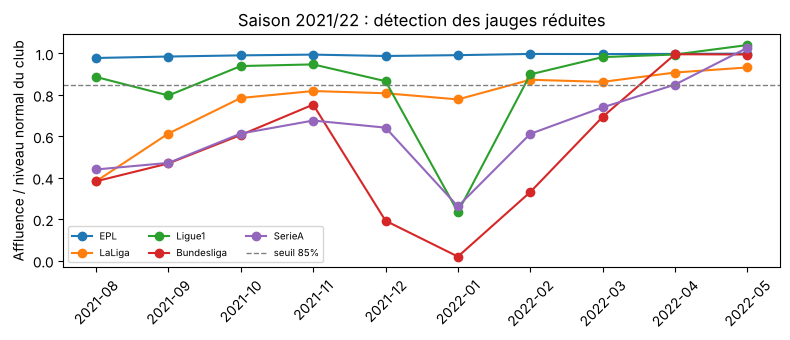

Matchs à jauge réduite détectés : 873


ligue,ENG-Premier League,ESP-La Liga,FRA-Ligue 1,GER-Bundesliga,ITA-Serie A
mois,,,,,
2021-08,0.9800,0.3800,0.8900,0.3800,0.4400
2021-09,0.9800,0.6100,0.8000,0.4700,0.4700
2021-10,0.9900,0.7800,0.9400,0.6100,0.6100
2021-11,0.9900,0.8200,0.9500,0.7500,0.6800
2021-12,0.9900,0.8100,0.8700,0.1900,0.6400
2022-01,0.9900,0.7800,0.2300,0.0200,0.2600
2022-02,1.0000,0.8700,0.9000,0.3300,0.6100
2022-03,1.0000,0.8600,0.9800,0.6900,0.7400
2022-04,1.0000,0.9100,0.9900,1.0000,0.8500


In [13]:
X["club"] = X.ligue + "|" + X.equipe_dom
X["unite"] = X.ligue + "|" + X.Season + "|" + X.equipe_dom + "|" + X.stade.fillna("inconnu")   # club x season x stadium
X["n_matchs_stade"] = X.groupby("unite").unite.transform("size")
X["stade_ponctuel"] = X.n_matchs_stade < MIN_MATCHS_STADE

base_normale = X.apparie & (X.periode == "normale") & ~X.manquante & ~X.stade_ponctuel
mediane_unite = X[base_normale].groupby("unite").affluence.median()
X["rel_unite"] = X.affluence / X.unite.map(mediane_unite)
suspect_unite = (X.affluence < SEUIL_ABERRANT) | (X.rel_unite < SEUIL_REL_ABERRANT)
mediane_club = X[base_normale & ~suspect_unite].groupby("club").affluence.median()   # normal level of the club
X["rel_club"] = X.affluence / X.club.map(mediane_club)
X["mois"] = X.date.dt.to_period("M").astype(str)

covid_mois = (X[X.periode_jauges & ~X.manquante].groupby(["ligue", "mois"]).rel_club.median()
                .rename("affluence_relative_mediane").reset_index())
covid_mois["jauge_reduite"] = covid_mois.affluence_relative_mediane < SEUIL_JAUGE
mois_reduits = set(zip(covid_mois.loc[covid_mois.jauge_reduite, "ligue"], covid_mois.loc[covid_mois.jauge_reduite, "mois"]))
X["jauge_reduite"] = [(l, m) in mois_reduits for l, m in zip(X.ligue, X.mois)]

tab = covid_mois.pivot(index="mois", columns="ligue", values="affluence_relative_mediane")
fig, ax = plt.subplots(figsize=(8, 3.5))
for ligue in tab.columns:
    ax.plot(tab.index, tab[ligue], marker="o", label=NOM_COURT[ligue])
ax.axhline(SEUIL_JAUGE, color="grey", ls="--", lw=1, label=f"seuil {SEUIL_JAUGE:.0%}")
ax.set_ylabel("Affluence / niveau normal du club"); ax.set_title("Saison 2021/22 : détection des jauges réduites")
ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=7, ncol=3); plt.tight_layout()
fig.savefig(DOSSIER_SORTIE / "fig_detection_jauges.png", dpi=150); plt.show()
print(f"Matchs à jauge réduite détectés : {X.jauge_reduite.sum()}")
tab.round(2)

### 2.5 Valeurs aberrantes et matchs délocalisés

Hors huis clos et hors mois à jauge réduite, une affluence inférieure à 1 000 spectateurs, ou à 25 % de la médiane du club dans le même stade et la même saison (à défaut, de sa médiane habituelle), ou supérieure à 115 % de la capacité réelle du stade, est classée aberrante : erreur de saisie ou huis clos disciplinaire (fermeture de tribunes). Un match joué dans un stade que le club n'utilise pas au moins 4 fois dans la saison est classé délocalisé (terrain neutre, travaux ponctuels, erreur de stade). Les déménagements en cours de saison (Lyon 2015/16, Tottenham 2018/19) ne sont pas touchés : la référence est le couple club × stade.

In [14]:
X["rel_reference"] = X.rel_unite.fillna(X.rel_club)
X["aberrante"] = (X.apparie & ~X.manquante & ~X.huis_clos & ~X.jauge_reduite
                  & ((X.affluence < SEUIL_ABERRANT) | (X.rel_reference < SEUIL_REL_ABERRANT)
                     | (X.affluence > SEUIL_DEPASSEMENT * X.capacite)))
aberrantes = X[X.aberrante][["ligue", "Season", "date", "equipe_dom", "equipe_ext", "affluence", "capacite", "stade", "rel_reference"]]
delocalises = X[X.apparie & X.stade_ponctuel & (X.periode == "normale")][
    ["ligue", "Season", "date", "equipe_dom", "equipe_ext", "affluence", "stade", "n_matchs_stade"]]
print(f"Affluences aberrantes : {len(aberrantes)} | matchs délocalisés (période normale) : {len(delocalises)}")
display(aberrantes.sort_values("affluence"))
delocalises.head(15)

Affluences aberrantes : 35 | matchs délocalisés (période normale) : 15


,ligue,Season,date,equipe_dom,equipe_ext,affluence,capacite,stade,rel_reference
4663,ESP-La Liga,2019-20,2019-10-19,Getafe,Leganés,13.0000,NaN,Coliseum Alfonso Pérez,0.0012
4153,ESP-La Liga,2017-18,2018-04-22,Atlético Madrid,Real Betis,200.0000,"67,703.0000",Estadio Wanda Metropolitano,0.0036
14349,ITA-Serie A,2016-17,2016-09-18,Crotone,Palermo,510.0000,"20,476.0000",Stadio Adriatico-Giovanni Cornacchia,0.0573
14370,ITA-Serie A,2016-17,2016-09-26,Crotone,Atalanta,522.0000,"20,476.0000",Stadio Adriatico-Giovanni Cornacchia,0.0586
7280,FRA-Ligue 1,2016-17,2016-09-16,Caen,Paris SG,740.0000,"20,453.0000",Stade Michel d'Ornano,0.0455
14326,ITA-Serie A,2016-17,2016-08-28,Crotone,Genoa,821.0000,"20,476.0000",Stadio Adriatico-Giovanni Cornacchia,0.0922
14365,ITA-Serie A,2016-17,2016-09-25,Lazio,Empoli,"1,000.0000","72,698.0000",Stadio Olimpico,0.0500
7664,FRA-Ligue 1,2017-18,2017-09-09,Troyes,Toulouse,"1,060.0000","20,420.0000",Stade de l'Aube,0.0961
17480,ITA-Serie A,2024-25,2024-11-25,Empoli,Udinese,"1,449.0000","16,167.0000",Stadio Carlo Castellani - Computer Gross...,0.1404
7621,FRA-Ligue 1,2017-18,2017-08-05,Lyon,Strasbourg,"1,979.0000","59,186.0000",Groupama Stadium,0.0417


,ligue,Season,date,equipe_dom,equipe_ext,affluence,stade,n_matchs_stade
3866,ESP-La Liga,2017-18,2017-09-20,Dep. La Coruña,Alavés,"18,518.0000",Estadio Abanca-Riazor,1
4208,ESP-La Liga,2018-19,2018-08-20,Athletic Club,Leganés,"38,327.0000",Estadio San Mamés,3
4230,ESP-La Liga,2018-19,2018-09-15,Athletic Club,Real Madrid,"46,413.0000",Estadio San Mamés,3
4252,ESP-La Liga,2018-19,2018-09-26,Athletic Club,Villarreal,"39,672.0000",Estadio San Mamés,3
6280,ESP-La Liga,2023-24,2024-01-02,Getafe,Rayo Vallecano,"11,204.0000",Estadio Cívitas Metropolitano,1
7715,FRA-Ligue 1,2017-18,2017-10-21,Amiens,Bordeaux,"12,297.0000",Stade Océane,1
10806,ENG-Premier League,2016-17,2017-04-04,Leicester City,Sunderland,"31,757.0000",Vicarage Road Stadium,1
10808,ENG-Premier League,2016-17,2017-04-04,Watford,West Brom,"20,090.0000",King Power Stadium,1
10844,ENG-Premier League,2016-17,2017-04-26,Crystal Palace,Tottenham,"25,596.0000",Goodison Park,1
14326,ITA-Serie A,2016-17,2016-08-28,Crotone,Genoa,821.0000,Stadio Adriatico-Giovanni Cornacchia,3


### 2.6 Biais de déclaration : affluences arrondies

Une affluence exactement multiple de 1 000 est probablement une valeur annoncée (capacité, estimation du club) plutôt qu'un comptage. Une part élevée signale une mesure moins précise, et une tendance à afficher la capacité quand le stade est plein.

In [15]:
obs = X[X.apparie & ~X.manquante & (X.periode == "normale")]
arrondis = obs.groupby("ligue").affluence.agg(
    matchs="size",
    multiple_1000=lambda s: (s % 1000 == 0).mean(),
    multiple_100=lambda s: (s % 100 == 0).mean(),
    multiple_10=lambda s: (s % 10 == 0).mean())
arrondis[["multiple_1000", "multiple_100", "multiple_10"]] = (100 * arrondis[["multiple_1000", "multiple_100", "multiple_10"]]).round(1)
arrondis["attendu_si_comptage_1000"] = 0.1
arrondis.rename(columns=lambda c: c if c == "matchs" else c + " (%)")

,matchs,multiple_1000 (%),multiple_100 (%),multiple_10 (%),attendu_si_comptage_1000 (%)
ligue,,,,,
ENG-Premier League,2946,0.1000,0.9000,9.2000,0.1000
ESP-La Liga,2928,0.3000,1.3000,10.5000,0.1000
FRA-Ligue 1,2502,2.5000,4.2000,13.5000,0.1000
GER-Bundesliga,2365,22.8000,40.0000,52.5000,0.1000
ITA-Serie A,2906,9.6000,12.1000,20.6000,0.1000


### 2.7 Taux de remplissage réel et censure par la capacité (hors saisons COVID)

Taux de remplissage = affluence ÷ capacité réelle du stade (section 1.6), calculé sur les sept saisons hors COVID. Une affluence légèrement supérieure à la capacité (jusqu'à 115 %) vient le plus souvent d'une capacité publiée avant un agrandissement ou de places debout ; le taux est alors ramené à 100 %. Au-delà, l'affluence est une erreur de saisie (section 2.5).

Quand un stade est plein, l'affluence ne peut plus augmenter, quelle que soit l'attractivité du match : la relation avec l'indice est alors **atténuée** (censure). La section 3.8 en tient compte avec un modèle Tobit.

In [16]:
retenu = (X.apparie & ~X.manquante & ~X.huis_clos & ~X.jauge_reduite & ~X.aberrante
          & ~X.stade_ponctuel & ~X.tapis_vert)
X["saison_covid"] = X.Season.isin(SAISONS_COVID)
X["taux_brut"] = X.affluence / X.capacite
X["remplissage"] = np.where(retenu & ~X.saison_covid & X.capacite.notna(), np.minimum(X.taux_brut, 1.0), np.nan)
mediane_rempl = X.groupby("unite").remplissage.median()
X["unite_non_pleine"] = (X.unite.map(mediane_rempl) < SEUIL_NON_PLEIN).fillna(False)

au_dela = X[retenu & (X.taux_brut > 1.02)][["ligue", "Season", "date", "equipe_dom", "equipe_ext", "stade",
                                            "affluence", "capacite", "taux_brut"]].sort_values("taux_brut", ascending=False)
R = X[X.remplissage.notna()]
censure = R.groupby("ligue").agg(
    matchs=("remplissage", "size"),
    capacite_moyenne=("capacite", "mean"),
    remplissage_moyen=("remplissage", "mean"),
    remplissage_median=("remplissage", "median"),
    part_pleins=("remplissage", lambda s: (s >= SEUIL_PLEIN).mean()),
    part_clubs_non_pleins=("unite_non_pleine", "mean"),
    part_au_dela_capacite=("taux_brut", lambda s: (s > 1.02).mean()))
censure.loc["Total"] = [len(R), R.capacite.mean(), R.remplissage.mean(), R.remplissage.median(),
                        (R.remplissage >= SEUIL_PLEIN).mean(), R.unite_non_pleine.mean(), (R.taux_brut > 1.02).mean()]
for c in ["remplissage_moyen", "remplissage_median", "part_pleins", "part_clubs_non_pleins", "part_au_dela_capacite"]:
    censure[c] = (100 * censure[c]).round(1)
censure["capacite_moyenne"] = censure["capacite_moyenne"].round(0)
print(f"Matchs avec un taux de remplissage réel (saisons hors COVID) : {len(R):,}")
print(f"Affluences entre 102 % et 115 % de la capacité (ramenées à 100 %) : {len(au_dela)}")
censure.rename(columns={"remplissage_moyen": "remplissage moyen (%)", "remplissage_median": "remplissage médian (%)",
                        "part_pleins": "matchs >= 95 % (%)", "part_clubs_non_pleins": "matchs de clubs non pleins (%)",
                        "part_au_dela_capacite": "au-delà de la capacité (%)"})

Matchs avec un taux de remplissage réel (saisons hors COVID) : 12,561
Affluences entre 102 % et 115 % de la capacité (ramenées à 100 %) : 84


,matchs,capacite_moyenne,remplissage moyen (%),remplissage médian (%),matchs >= 95 % (%),matchs de clubs non pleins (%),au-delà de la capacité (%)
ligue,,,,,,,
ENG-Premier League,2652,"39,621.0000",96.7000,98.6000,81.3000,4.8000,1.5000
ESP-La Liga,2651,"37,399.0000",75.5000,77.8000,6.1000,93.6000,0.4000
FRA-Ligue 1,2496,"32,611.0000",71.0000,72.7000,11.5000,85.6000,0.3000
GER-Bundesliga,2140,"45,164.0000",93.4000,98.5000,66.0000,19.9000,0.7000
ITA-Serie A,2622,"39,144.0000",69.5000,70.6000,13.4000,81.2000,0.5000
Total,12561,"38,604.0000",80.9000,86.9000,34.8000,58.1000,0.7000


### 2.8 Échantillon d'analyse et biais de sélection

Le tableau de flux donne le nombre de matchs restant après chaque exclusion. On compare ensuite les matchs retenus aux matchs exclus : si les exclusions touchaient surtout des matchs à fort ou faible indice, les résultats seraient biaisés. L'écart standardisé (différence des moyennes divisée par l'écart-type commun) est considéré comme négligeable en dessous de 0,1 en valeur absolue.

In [17]:
etapes = [("Matchs de l'article", pd.Series(True, index=X.index)),
          ("appariés à FBref", X.apparie),
          ("affluence renseignée", ~X.manquante),
          ("hors huis clos", ~X.huis_clos),
          ("hors jauges réduites", ~X.jauge_reduite),
          ("hors valeurs aberrantes", ~X.aberrante),
          ("hors matchs délocalisés", ~X.stade_ponctuel),
          ("hors tapis vert", ~X.tapis_vert)]
masque, lignes = pd.Series(True, index=X.index), []
for libelle, condition in etapes:
    masque = masque & condition
    lignes.append({"etape": libelle, "matchs_restants": int(masque.sum())})
flux = pd.DataFrame(lignes)
flux["exclus_a_cette_etape"] = (-flux.matchs_restants.diff()).fillna(0).astype(int)
X["echantillon"] = masque
assert (X.echantillon == retenu).all()
display(flux)

VARS = ["MBCI_star", "G_k", "U_k", "W_k", "incert_exante", "P_H"]
sel = []
for v in VARS:
    a, b = X.loc[X.echantillon, v], X.loc[~X.echantillon, v]
    smd = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    sel.append({"variable": v, "moyenne_retenus": a.mean(), "moyenne_exclus": b.mean(),
                "ecart_standardise": smd, "p_welch": stats.ttest_ind(a, b, equal_var=False).pvalue})
selection = pd.DataFrame(sel).set_index("variable")
print(f"Échantillon d'analyse : {X.echantillon.sum():,} matchs ({X.echantillon.mean():.1%}) | exclus : {(~X.echantillon).sum():,}")
selection

,etape,matchs_restants,exclus_a_cette_etape
0,Matchs de l'article,17732,0
1,appariés à FBref,17732,0
2,affluence renseignée,15561,2171
3,hors huis clos,15440,121
4,hors jauges réduites,14592,848
5,hors valeurs aberrantes,14557,35
6,hors matchs délocalisés,14546,11
7,hors tapis vert,14543,3


Échantillon d'analyse : 14,543 matchs (82.0%) | exclus : 3,189


,moyenne_retenus,moyenne_exclus,ecart_standardise,p_welch
variable,,,,
MBCI_star,0.3588,0.3644,-0.0492,0.0121
G_k,0.4554,0.4611,-0.0235,0.2296
U_k,0.5852,0.5880,-0.0157,0.4233
W_k,0.3822,0.3924,-0.0479,0.0148
incert_exante,0.5849,0.5839,0.0122,0.5287
P_H,0.4430,0.4429,0.0008,0.9671


**Lecture.** Les exclusions sont presque entièrement dues à la période COVID. Les matchs exclus ne diffèrent pas des matchs retenus par leur indice ou leurs composantes : tous les écarts standardisés sont inférieurs à 0,05 en valeur absolue. Les $p$ faibles pour $MBCI^*_k$ et $W_k$ tiennent à la taille de l'échantillon, pas à un écart important. L'échantillon d'analyse n'est donc pas sélectionné selon la compétitivité des matchs.

### 2.9 Exports de la vérification

`controle_donnees.xlsx` contient une feuille par contrôle ; `donnees_affluence_mbci.xlsx` contient tous les matchs de l'article avec leur affluence, les indicateurs de vérification et la colonne `echantillon` (matchs retenus).

In [18]:
exporter("controle_donnees.xlsx", {
    "flux_echantillon": flux,
    "completude": comp.reset_index(),
    "appariement_noms": noms,
    "ecarts_score": ecarts_score,
    "manquantes": manq,
    "covid_jauges": covid_mois,
    "aberrantes": aberrantes,
    "delocalises": delocalises,
    "arrondis": arrondis,
    "capacites_wikipedia": capacites,
    "attribution_capacites": attrib,
    "au_dela_capacite": au_dela,
    "censure_capacite": censure,
    "biais_selection": selection.reset_index(),
})
colonnes_export = ["League", "ligue", "Season", "Gameweek", "date", "jour", "heure", "HomeTeam", "AwayTeam",
                   "equipe_dom", "equipe_ext", "FTHG", "FTAG", "stade", "affluence", "capacite", "remplissage",
                   "G_k", "U_k", "W_k", "W_raw", "W_cat", "MBCI_star", "P_H", "P_N", "P_A", "incert_exante",
                   "periode", "saison_covid", "manquante", "jauge_reduite", "aberrante", "stade_ponctuel", "tapis_vert", "echantillon"]
exporter("donnees_affluence_mbci.xlsx", {"matchs": X[colonnes_export]})

Écrit : controle_donnees.xlsx (flux_echantillon, completude, appariement_noms, ecarts_score, manquantes, covid_jauges, aberrantes, delocalises, arrondis, capacites_wikipedia, attribution_capacites, au_dela_capacite, censure_capacite, biais_selection)


Écrit : donnees_affluence_mbci.xlsx (matchs)


## 3. L'indice est-il corrélé avec l'affluence ?

### 3.1 Mesures et stratégie

L'affluence d'un match dépend d'abord de la taille du club qui reçoit et de son stade : le Borussia Dortmund attire 80 000 spectateurs quel que soit le match. Elle dépend aussi du moment de la saison (météo, vacances, dernières journées festives), alors que l'enjeu $W_k$ croît mécaniquement avec l'avancement $t/T$. Une corrélation brute mélange donc la compétitivité du match, la taille des clubs et le calendrier.

La comparaison retenue se fait **à l'intérieur d'un même club recevant, d'un même stade et d'une même saison, et entre matchs d'une même journée** : à la même journée, $t/T$ est identique pour tous les matchs, si bien que les écarts d'enjeu ne viennent que du classement.

- **Variable expliquée** : $\ln(\text{affluence})$ ; un coefficient $b$ se lit comme une variation d'environ $100\,b$ %.
- **Effets fixes club × stade × saison** : taille du club, capacité du stade, prix des billets, popularité du club dans la saison.
- **Effets fixes journée** (championnat × saison × journée) : moment de la saison, météo, calendrier commun.
- **Contrôles** : club visiteur (attractivité de l'adversaire), jour de la semaine, créneau horaire.
- **Erreurs-types** groupées par club recevant.
- **Effet d'un écart-type** (`effet_1_ecart_type`) : variation en % de l'affluence pour une hausse d'un écart-type de la variable, mesuré après effets fixes et contrôles ; **effet de 0 à 1** (`effet_0_a_1`) : variation en % quand la variable passe de 0 à 1 (toutes les variables sont dans $[0,1]$).

Les deux effets fixes sont absorbés par projections alternées, puis les contrôles par le théorème de Frisch–Waugh–Lovell : les coefficients sont identiques à ceux d'une régression avec toutes les indicatrices.

In [19]:
S = X[X.echantillon].copy()
S["log_aff"] = np.log(S.affluence)
S["aff_relative"] = S.affluence / S.groupby("unite").affluence.transform("mean")
S["creneau"] = pd.cut(S.heure, [0, 15.5, 18.5, 25], right=False,
                      labels=["avant 15h30", "15h30-18h30", "après 18h30"]).astype(str)
S["mois_cal"] = S.date.dt.month.astype(str)
S["journee"] = S.ligue + "|" + S.Season + "|" + S.Gameweek.astype(str)
S["adverse"] = S.ligue + "|" + S.equipe_ext
S["ligue_saison"] = S.ligue + "|" + S.Season
NOMS = {"MBCI_star": "MBCI*_k (indice)", "G_k": "G_k intensité (ex post)", "U_k": "U_k surprise (ex post)",
        "W_k": "W_k enjeu (ex ante)", "W_raw": "max sigma, enjeu sans t/T (ex ante)",
        "incert_exante": "incertitude ex ante", "P_H": "P(victoire à domicile)"}

desc = S.groupby("ligue").agg(matchs=("affluence", "size"), clubs_saisons=("unite", "nunique"),
                              affluence_moyenne=("affluence", "mean"), affluence_mediane=("affluence", "median"),
                              remplissage_moyen_hors_covid=("remplissage", "mean"), MBCI_moyen=("MBCI_star", "mean"))
desc.loc["Total"] = [len(S), S.unite.nunique(), S.affluence.mean(), S.affluence.median(), S.remplissage.mean(), S.MBCI_star.mean()]
desc.round(3)

,matchs,clubs_saisons,affluence_moyenne,affluence_mediane,remplissage_moyen_hors_covid,MBCI_moyen
ligue,,,,,,
ENG-Premier League,3319,181,"38,531.6610","32,186.0000",0.9670,0.3570
ESP-La Liga,3082,181,"28,466.1130","20,501.5000",0.7550,0.3510
FRA-Ligue 1,2797,157,"23,508.4130","19,369.0000",0.7100,0.3620
GER-Bundesliga,2427,162,"41,829.4560","40,193.0000",0.9340,0.3750
ITA-Serie A,2918,181,"26,673.5810","20,982.5000",0.6950,0.3520
Total,14543,862,"31,680.2430","27,233.0000",0.8090,0.3590


### 3.2 Corrélations simples et intra-club

Pour chaque mesure d'affluence : corrélation de Pearson ($r$), de Spearman ($\rho$, sur les rangs) et corrélation **intra** (après avoir retiré la moyenne de chaque club × stade × saison).

In [20]:
MESURES_Y = {"affluence": "affluence", "log_aff": "ln(affluence)", "aff_relative": "affluence / moyenne du club-saison",
             "remplissage": "taux de remplissage réel (hors saisons COVID)"}
lignes = []
for y, nom_y in MESURES_Y.items():
    d = S.dropna(subset=[y])
    for v in VARS:
        r, p = stats.pearsonr(d[v], d[y])
        rho, p_rho = stats.spearmanr(d[v], d[y])
        intra = d[[v, y]] - d.groupby("unite")[[v, y]].transform("mean")
        r_in, p_in = stats.pearsonr(intra[v], intra[y])
        lignes.append({"affluence_mesuree": nom_y, "variable": NOMS[v], "n": len(d), "r": r, "p": p,
                       "rho_spearman": rho, "p_spearman": p_rho, "r_intra": r_in, "p_intra": p_in})
correlations = pd.DataFrame(lignes)
correlations[correlations.affluence_mesuree.isin(["affluence", "ln(affluence)"])].round(3)

,affluence_mesuree,variable,n,r,p,rho_spearman,p_spearman,r_intra,p_intra
0,affluence,MBCI*_k (indice),14543,-0.0650,0.0000,-0.0570,0.0000,0.0230,0.0050
1,affluence,G_k intensité (ex post),14543,0.0750,0.0000,0.0720,0.0000,0.0170,0.0440
2,affluence,U_k surprise (ex post),14543,-0.2050,0.0000,-0.1390,0.0000,0.0170,0.0470
3,affluence,W_k enjeu (ex ante),14543,-0.0110,0.1820,-0.0130,0.1260,0.0050,0.5350
4,affluence,incertitude ex ante,14543,-0.3510,0.0000,-0.3140,0.0000,0.0170,0.0420
5,affluence,P(victoire à domicile),14543,0.3920,0.0000,0.3600,0.0000,-0.2960,0.0000
6,ln(affluence),MBCI*_k (indice),14543,-0.0570,0.0000,-0.0570,0.0000,0.0090,0.2970
7,ln(affluence),G_k intensité (ex post),14543,0.0710,0.0000,0.0720,0.0000,0.0200,0.0170
8,ln(affluence),U_k surprise (ex post),14543,-0.1820,0.0000,-0.1390,0.0000,-0.0200,0.0140
9,ln(affluence),W_k enjeu (ex ante),14543,-0.0130,0.1040,-0.0130,0.1260,0.0100,0.2380


**Lecture.** Les corrélations brutes sont dominées par la taille des clubs : les grands clubs ont plus de spectateurs et sont plus souvent favoris à domicile, d'où une corrélation positive avec $P(\text{victoire à domicile})$ et négative avec la surprise et l'incertitude. À l'intérieur d'un club-saison, ces corrélations disparaissent ou changent de signe ($P(\text{victoire à domicile})$ devient négative : un adversaire fort attire du monde). Elles ne disent donc rien de l'effet de la compétitivité, d'où les régressions à effets fixes ci-dessous.

### 3.3 Régressions à effets fixes

Quatre spécifications :
1. l'indice seul ;
2. ses trois composantes ;
3. les seules variables connues **avant** le match (enjeu, incertitude ex ante, probabilité de victoire à domicile) ;
4. les variables ex ante **et** les composantes ex post : si $G_k$ et $U_k$, connues seulement après le match, étaient significatives, ce serait le signe d'un facteur commun non contrôlé (test placebo).

In [21]:
EFFETS_FIXES = ["unite", "journee"]          # club x stadium x season; league x season x round
CONTROLES = ["adverse", "jour", "creneau"]


def absorber(A, codes, tol=1e-9, max_iter=1000):
    # Removes from each column of A the means of several groups (alternating projections).
    projections = []
    for c in codes:
        G = sparse.csr_matrix((np.ones(len(c)), (np.arange(len(c)), c)))
        projections.append((G, np.asarray(G.sum(axis=0)).ravel()))
    A = np.array(A, dtype=float)
    for _ in range(max_iter):
        avant = A.copy()
        for G, n_g in projections:
            A -= G @ ((G.T @ A) / n_g[:, None])
        if len(projections) == 1 or np.abs(A - avant).max() < tol:
            break
    return A


def regression_fe(df, xvars, y="log_aff", effets_fixes=EFFETS_FIXES, controles=CONTROLES, cluster="club"):
    # OLS with absorbed fixed effects, controls partialled out (Frisch-Waugh-Lovell), clustered standard errors.
    # Effects in % of attendance if y is a logarithm, in fill-rate points otherwise.
    codes = [df[g].astype("category").cat.codes.values for g in effets_fixes]
    Z = absorber(df[[y] + xvars].values, codes)
    if controles:
        D = pd.get_dummies(df[controles].astype(str), drop_first=True, dtype=float).values
        D = absorber(D, codes)
        beta, *_ = np.linalg.lstsq(D, Z, rcond=None)
        Z = Z - D @ beta
    Z = pd.DataFrame(Z, columns=[y] + xvars, index=df.index)
    m = sm.OLS(Z[y], Z[xvars]).fit(cov_type="cluster", cov_kwds={"groups": df[cluster].astype("category").cat.codes})
    ic = m.conf_int()
    sd = Z[xvars].std()
    en_log = y.startswith("log")
    return pd.DataFrame({"coef": m.params, "erreur_type": m.bse, "t": m.tvalues, "p": m.pvalues,
                         "ic95_bas": ic[0], "ic95_haut": ic[1],
                         "effet_1_ecart_type": 100 * (np.exp(m.params * sd) - 1) if en_log else 100 * m.params * sd,
                         "effet_0_a_1": 100 * (np.exp(m.params) - 1) if en_log else 100 * m.params,
                         "unite_effet": "% d'affluence" if en_log else "points de remplissage",
                         "n": int(m.nobs), "clubs": df[cluster].nunique(), "R2_intra": m.rsquared})


SPECS = {"(1) indice": ["MBCI_star"],
         "(2) composantes": ["G_k", "U_k", "W_k"],
         "(3) ex ante": ["W_k", "incert_exante", "P_H"],
         "(4) ex ante + ex post": ["W_k", "incert_exante", "P_H", "G_k", "U_k"]}


def empiler(resultats):
    t = pd.concat(resultats, names=["specification", "variable"]).reset_index()
    t["variable"] = t["variable"].map(NOMS)
    return t


regressions = empiler({nom: regression_fe(S, xv) for nom, xv in SPECS.items()})
regressions[["specification", "variable", "coef", "erreur_type", "p", "effet_1_ecart_type", "effet_0_a_1", "n"]].round(4)

,specification,variable,coef,erreur_type,p,effet_1_ecart_type,effet_0_a_1,n
0,(1) indice,MBCI*_k (indice),0.0084,0.0108,0.4322,0.0781,0.8481,14543
1,(2) composantes,G_k intensité (ex post),-0.0050,0.0053,0.3437,-0.1077,-0.5028,14543
2,(2) composantes,U_k surprise (ex post),0.0019,0.0069,0.7836,0.0288,0.1900,14543
3,(2) composantes,W_k enjeu (ex ante),0.0591,0.0136,0.0000,0.5513,6.0829,14543
4,(3) ex ante,W_k enjeu (ex ante),0.0574,0.0135,0.0000,0.5360,5.9095,14543
5,(3) ex ante,incertitude ex ante,-0.0418,0.0384,0.2769,-0.2299,-4.0929,14543
6,(3) ex ante,P(victoire à domicile),-0.0072,0.0182,0.6905,-0.0428,-0.7214,14543
7,(4) ex ante + ex post,W_k enjeu (ex ante),0.0571,0.0135,0.0000,0.5330,5.8754,14543
8,(4) ex ante + ex post,incertitude ex ante,-0.0497,0.0394,0.2071,-0.2733,-4.8475,14543
9,(4) ex ante + ex post,P(victoire à domicile),-0.0076,0.0182,0.6762,-0.0449,-0.7568,14543


### 3.4 Affluence selon l'enjeu et selon l'indice

Nuage par déciles : l'affluence et la variable sont d'abord nettoyées des effets fixes et des contrôles, puis on trace l'affluence résiduelle moyenne (en %) par décile de la variable nettoyée, avec un intervalle de confiance à 95 %. La pente du nuage est celle de la régression.

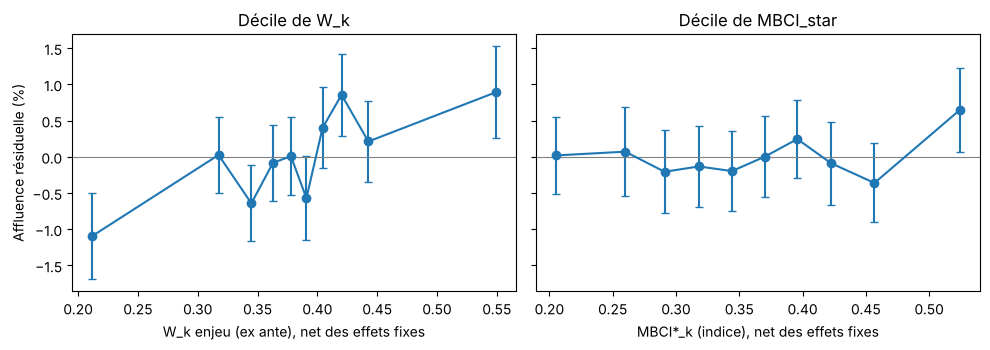

In [22]:
def nettoyer_fe(df, cols, effets_fixes=EFFETS_FIXES, controles=CONTROLES):
    codes = [df[g].astype("category").cat.codes.values for g in effets_fixes]
    Z = absorber(df[cols].values, codes)
    D = absorber(pd.get_dummies(df[controles].astype(str), drop_first=True, dtype=float).values, codes)
    beta, *_ = np.linalg.lstsq(D, Z, rcond=None)
    return pd.DataFrame(Z - D @ beta, columns=cols, index=df.index)


deciles = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, v in zip(axes, ["W_k", "MBCI_star"]):
    R = nettoyer_fe(S, ["log_aff", v])
    q = pd.qcut(R[v].rank(method="first"), 10, labels=False) + 1
    g = R.groupby(q).agg(x=(v, "mean"), r=("log_aff", "mean"), se=("log_aff", "sem"), n=(v, "size"))
    g["x"] = g["x"] + S[v].mean()
    g["affluence_residuelle_pct"], g["ic95_pct"] = 100 * g.r, 196 * g.se
    ax.errorbar(g.x, g.affluence_residuelle_pct, yerr=g.ic95_pct, marker="o", capsize=3)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(f"{NOMS[v]}, net des effets fixes"); ax.set_title(f"Décile de {v}")
    deciles.append(g.assign(variable=NOMS[v]).reset_index(names="decile"))
axes[0].set_ylabel("Affluence résiduelle (%)")
plt.tight_layout(); fig.savefig(DOSSIER_SORTIE / "fig_affluence_deciles.png", dpi=150); plt.show()
deciles = pd.concat(deciles)[["variable", "decile", "n", "x", "affluence_residuelle_pct", "ic95_pct"]]

### 3.5 Par championnat

Spécifications (1) et (4), estimées séparément dans chaque championnat. Les championnats aux stades presque toujours pleins (Premier League, Bundesliga, section 2.7) laissent peu de place à une variation de l'affluence.

In [23]:
par_ligue = []
for ligue, d in S.groupby("ligue"):
    for nom in ["(1) indice", "(4) ex ante + ex post"]:
        r = regression_fe(d, SPECS[nom]).assign(ligue=NOM_COURT[ligue], specification=nom)
        par_ligue.append(r.reset_index(names="variable"))
par_ligue = pd.concat(par_ligue)
par_ligue["variable"] = par_ligue["variable"].map(NOMS)
par_ligue = par_ligue[["ligue", "specification", "variable", "coef", "erreur_type", "p",
                       "effet_1_ecart_type", "effet_0_a_1", "n", "clubs"]]
par_ligue.pivot_table(index="variable", columns="ligue", values=["coef", "p"], aggfunc="first").round(3)

coef                                          p                            
ligue                   Bundesliga     EPL  LaLiga  Ligue1  SerieA Bundesliga    EPL LaLiga Ligue1 SerieA
variable                                                                                                 
G_k intensité (ex post)    -0.0010 -0.0010 -0.0210 -0.0200  0.0190     0.9140 0.6450 0.0040 0.2380 0.2860
MBCI*_k (indice)            0.0110 -0.0030  0.0170 -0.0210  0.0410     0.4700 0.7190 0.3950 0.4810 0.2710
P(victoire à domicile)     -0.0820  0.0110  0.0310  0.0010  0.0310     0.0440 0.3300 0.5810 0.9830 0.5470
U_k surprise (ex post)      0.0060 -0.0030  0.0280 -0.0030  0.0100     0.4780 0.6140 0.1030 0.8780 0.5140
W_k enjeu (ex ante)         0.0240  0.0080  0.1890  0.0140  0.0620     0.0450 0.2750 0.0000 0.6770 0.1070
incertitude ex ante        -0.0540  0.0050 -0.0430  0.1270 -0.1870     0.1550 0.8620 0.3490 0.4830 0.0510

### 3.6 Stades non pleins

Pour limiter la censure par la capacité, on ne garde que les clubs-saisons dont le remplissage **réel** médian est inférieur à 90 % (saisons hors COVID) : leur affluence peut réellement varier d'un match à l'autre. La sélection se fait au niveau du club-saison, pas du match, pour ne pas sélectionner sur la variable expliquée.

In [24]:
NP = S[S.unite_non_pleine]
print(f"Clubs-saisons non pleins : {NP.unite.nunique()} | matchs : {len(NP):,}")
non_pleins = empiler({nom: regression_fe(NP, xv) for nom, xv in SPECS.items()})
non_pleins[["specification", "variable", "coef", "erreur_type", "p", "effet_1_ecart_type", "effet_0_a_1", "n"]].round(4)

Clubs-saisons non pleins : 395 | matchs : 7,300


,specification,variable,coef,erreur_type,p,effet_1_ecart_type,effet_0_a_1,n
0,(1) indice,MBCI*_k (indice),0.0211,0.0210,0.3151,0.1880,2.1275,7300
1,(2) composantes,G_k intensité (ex post),-0.0138,0.0096,0.1513,-0.2875,-1.3739,7300
2,(2) composantes,U_k surprise (ex post),0.0191,0.0127,0.1337,0.2676,1.9272,7300
3,(2) composantes,W_k enjeu (ex ante),0.1108,0.0233,0.0000,1.0323,11.7150,7300
4,(3) ex ante,W_k enjeu (ex ante),0.1104,0.0230,0.0000,1.0289,11.6745,7300
5,(3) ex ante,incertitude ex ante,0.0280,0.0717,0.6960,0.1388,2.8396,7300
6,(3) ex ante,P(victoire à domicile),0.0356,0.0319,0.2638,0.1894,3.6251,7300
7,(4) ex ante + ex post,W_k enjeu (ex ante),0.1102,0.0229,0.0000,1.0269,11.6506,7300
8,(4) ex ante + ex post,incertitude ex ante,0.0102,0.0748,0.8914,0.0506,1.0263,7300
9,(4) ex ante + ex post,P(victoire à domicile),0.0346,0.0319,0.2769,0.1843,3.5254,7300


**Effet de l'enjeu selon le remplissage habituel du club.** Chaque club × stade × saison est classé selon son taux de remplissage réel médian (saisons hors COVID), puis la spécification (4) est estimée dans chaque groupe, avec les mêmes effets fixes et contrôles. Si la faiblesse de l'effet moyen vient de la censure par la capacité, l'effet de l'enjeu doit décroître à mesure que le stade se remplit, et disparaître quand il est toujours plein. L'effet est donné en % d'affluence et en points de remplissage. Le tableau suivant reprend les clubs non pleins par championnat (au moins 10 clubs-saisons).

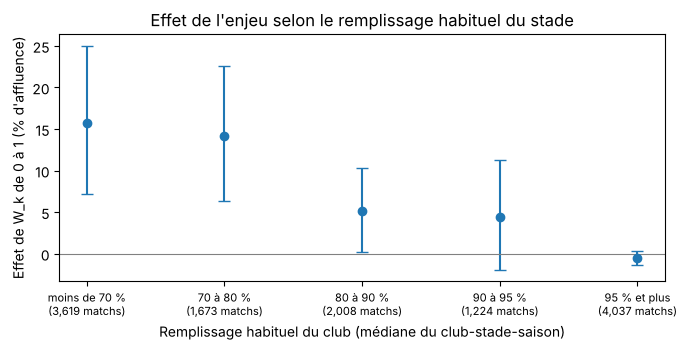

,ligue,clubs_saisons,matchs,effet_W_affluence_pct,p
0,EPL,7,128,NaN,NaN
1,LaLiga,132,2481,21.5964,0.0000
2,Ligue1,117,2137,4.3757,0.3244
3,Bundesliga,25,425,6.1109,0.3206
4,SerieA,114,2129,12.2171,0.0064


,remplissage_habituel,clubs_saisons,matchs,remplissage_moyen_pct,effet_W_affluence_pct,ic95_bas_pct,ic95_haut_pct,p,effet_W_points_remplissage,p_points
0,moins de 70 %,195,3619,58.5370,15.7790,7.2150,25.0270,0.0000,8.9480,0.0000
1,70 à 80 %,91,1673,76.2420,14.1370,6.3010,22.5500,0.0000,9.5830,0.0000
2,80 à 90 %,109,2008,84.1890,5.1170,0.1840,10.2930,0.0420,4.2880,0.0200
3,90 à 95 %,67,1224,92.1410,4.4400,-1.9300,11.2240,0.1760,3.8760,0.1010
4,95 % et plus,223,4037,97.8340,-0.5670,-1.4010,0.2750,0.1860,-0.3660,0.3310
5,non pleins (moins de 90 %),395,7300,69.6510,11.6510,6.7400,16.7870,0.0000,7.6110,0.0000
6,pleins (90 % et plus),290,5261,96.5090,-0.6440,-1.6150,0.3360,0.1970,-0.2600,0.5180


In [25]:
R6 = S[S.remplissage.notna()].copy()
R6["remplissage_habituel"] = R6.unite.map(mediane_rempl)
GROUPES = ["moins de 70 %", "70 à 80 %", "80 à 90 %", "90 à 95 %", "95 % et plus"]
R6["groupe"] = pd.cut(R6.remplissage_habituel, [0, 0.70, 0.80, 0.90, 0.95, 1.01], right=False, labels=GROUPES)
sous_ech = [(g, R6[R6.groupe == g]) for g in GROUPES]
sous_ech += [("non pleins (moins de 90 %)", R6[R6.remplissage_habituel < SEUIL_NON_PLEIN]),
             ("pleins (90 % et plus)", R6[R6.remplissage_habituel >= SEUIL_NON_PLEIN])]
lignes = []
for nom, d in sous_ech:
    a = regression_fe(d, SPECS["(4) ex ante + ex post"]).loc["W_k"]
    b = regression_fe(d, SPECS["(4) ex ante + ex post"], y="remplissage").loc["W_k"]
    lignes.append({"remplissage_habituel": nom, "clubs_saisons": d.unite.nunique(), "matchs": len(d),
                   "remplissage_moyen_pct": 100 * d.remplissage.mean(),
                   "effet_W_affluence_pct": a.effet_0_a_1, "ic95_bas_pct": 100 * (np.exp(a.ic95_bas) - 1),
                   "ic95_haut_pct": 100 * (np.exp(a.ic95_haut) - 1), "p": a.p,
                   "effet_W_points_remplissage": b.effet_0_a_1, "p_points": b.p})
enjeu_remplissage = pd.DataFrame(lignes)

lignes = []
for ligue, d in R6[R6.remplissage_habituel < SEUIL_NON_PLEIN].groupby("ligue"):
    if d.unite.nunique() < 10:
        lignes.append({"ligue": NOM_COURT[ligue], "clubs_saisons": d.unite.nunique(), "matchs": len(d)})
        continue
    a = regression_fe(d, SPECS["(4) ex ante + ex post"]).loc["W_k"]
    lignes.append({"ligue": NOM_COURT[ligue], "clubs_saisons": d.unite.nunique(), "matchs": len(d),
                   "effet_W_affluence_pct": a.effet_0_a_1, "p": a.p})
non_pleins_ligue = pd.DataFrame(lignes)

g = enjeu_remplissage.iloc[:len(GROUPES)]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(range(len(g)), g.effet_W_affluence_pct,
            yerr=[g.effet_W_affluence_pct - g.ic95_bas_pct, g.ic95_haut_pct - g.effet_W_affluence_pct],
            fmt="o", capsize=4)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(range(len(g)), [f"{n}\n({m:,} matchs)" for n, m in zip(g.remplissage_habituel, g.matchs)], fontsize=8)
ax.set_xlabel("Remplissage habituel du club (médiane du club-stade-saison)")
ax.set_ylabel("Effet de W_k de 0 à 1 (% d'affluence)")
ax.set_title("Effet de l'enjeu selon le remplissage habituel du stade")
plt.tight_layout(); fig.savefig(DOSSIER_SORTIE / "fig_enjeu_par_remplissage.png", dpi=150); plt.show()
display(non_pleins_ligue.round(4))
enjeu_remplissage.round(3)

### 3.7 Niveau ligue-saison

Corrélation entre l'indice saisonnier $MBCI_s$ et l'affluence moyenne, puis le taux de remplissage réel moyen (saisons hors COVID), de la ligue-saison. Elle est calculée sur l'ensemble des ligues-saisons, puis à l'intérieur des championnats (écarts à la moyenne de chaque championnat), seule comparaison qui ne mélange pas les différences structurelles entre pays.

In [26]:
LS = (S.groupby(["ligue", "Season"])
        .agg(matchs=("affluence", "size"), affluence_moyenne=("affluence", "mean"), remplissage_moyen=("remplissage", "mean"),
             MBCI_s=("MBCI_star", "mean"), G=("G_k", "mean"), U=("U_k", "mean"), W=("W_k", "mean"))
        .reset_index())
LS = LS[LS.matchs >= 100]          # sufficiently complete league-seasons
lignes = []
for y in ["affluence_moyenne", "remplissage_moyen"]:
    d = LS.dropna(subset=[y])
    for v in ["MBCI_s", "G", "U", "W"]:
        r, p = stats.pearsonr(d[v], d[y])
        intra = d[[v, y]] - d.groupby("ligue")[[v, y]].transform("mean")
        r_in, p_in = stats.pearsonr(intra[v], intra[y])
        lignes.append({"affluence": y, "variable": v, "n": len(d), "r": r, "p": p, "r_intra_ligue": r_in, "p_intra_ligue": p_in})
ligue_saison_cor = pd.DataFrame(lignes)
ligue_saison_cor.round(3)

,affluence,variable,n,r,p,r_intra_ligue,p_intra_ligue
0,affluence_moyenne,MBCI_s,42,0.4270,0.0050,0.1550,0.3260
1,affluence_moyenne,G,42,0.5530,0.0000,0.0430,0.7890
2,affluence_moyenne,U,42,-0.0750,0.6390,0.0770,0.6260
3,affluence_moyenne,W,42,0.0050,0.9760,0.0590,0.7100
4,remplissage_moyen,MBCI_s,35,0.4750,0.0040,0.2500,0.1470
5,remplissage_moyen,G,35,0.5190,0.0010,0.0670,0.7030
6,remplissage_moyen,U,35,-0.0260,0.8830,0.1110,0.5260
7,remplissage_moyen,W,35,0.1230,0.4810,0.1430,0.4120


### 3.8 Taux de remplissage réel (hors saisons COVID)

Le taux de remplissage rapporte l'affluence à la capacité réelle du stade (section 1.6). Contrairement à l'affluence brute, il est comparable d'un club à l'autre : 30 000 spectateurs remplissent le stade de Gérone mais à peine la moitié de San Siro. On peut donc comparer des matchs de **clubs différents** sans que la taille du club domine la comparaison. Calculs sur les sept saisons hors COVID (2015/16 à 2018/19 et 2022/23 à 2024/25).

Trois questions :
1. **Corrélations** : les matchs plus compétitifs sont-ils joués dans des stades plus pleins, toutes équipes confondues, puis à l'intérieur d'un club-saison ?
2. **Régressions** sur le taux de remplissage, avec trois niveaux de comparaison : entre clubs à la même journée (effets fixes journée), à l'intérieur d'un club sur plusieurs saisons (effets fixes club et journée), à l'intérieur d'un club-stade-saison (comparaison principale de la section 3.3). Les effets sont en **points de remplissage**.
3. **Modèle Tobit** : un stade plein censure la demande. Le Tobit traite les matchs à au moins 95 % de remplissage comme censurés et estime l'effet sur la **demande latente**, celle qui aurait été observée sans limite de capacité.

In [27]:
RS = S[S.remplissage.notna()].copy()
RS["plein"] = RS.remplissage >= SEUIL_PLEIN
rempl_desc = RS.groupby("ligue").agg(matchs=("remplissage", "size"), clubs_saisons=("unite", "nunique"),
                                     remplissage_moyen=("remplissage", "mean"), part_pleins=("plein", "mean"))
rempl_desc.loc["Total"] = [len(RS), RS.unite.nunique(), RS.remplissage.mean(), RS.plein.mean()]
q = pd.qcut(RS.W_k.rank(method="first"), 5, labels=["W très faible", "W faible", "W moyen", "W élevé", "W très élevé"])
rempl_desc_w = RS.groupby(q, observed=True).agg(W_moyen=("W_k", "mean"), remplissage_moyen=("remplissage", "mean"),
                                                part_pleins=("plein", "mean"), matchs=("remplissage", "size"))
print(f"Matchs : {len(RS):,} | remplissage moyen : {RS.remplissage.mean():.1%} | matchs pleins (>= 95 %) : {RS.plein.mean():.1%}")
print("\nRemplissage par quintile d'enjeu (toutes équipes confondues) :")
display(rempl_desc_w.round(3))
rempl_desc.round(3)

Matchs : 12,561 | remplissage moyen : 80.9% | matchs pleins (>= 95 %) : 34.8%

Remplissage par quintile d'enjeu (toutes équipes confondues) :


,W_moyen,remplissage_moyen,part_pleins,matchs
W_k,,,,
W très faible,0.0790,0.8060,0.3340,2513
W faible,0.2490,0.8150,0.3580,2512
W moyen,0.3960,0.7940,0.3290,2512
W élevé,0.5100,0.8090,0.3620,2512
W très élevé,0.6780,0.8220,0.3560,2512


,matchs,clubs_saisons,remplissage_moyen,part_pleins
ligue,,,,
ENG-Premier League,2652,141,0.9670,0.8130
ESP-La Liga,2651,141,0.7550,0.0610
FRA-Ligue 1,2496,137,0.7100,0.1150
GER-Bundesliga,2140,126,0.9340,0.6600
ITA-Serie A,2622,140,0.6950,0.1340
Total,12561,685,0.8090,0.3480


In [28]:
lignes = []
for v in VARS:
    r, p = stats.pearsonr(RS[v], RS.remplissage)
    rho, p_rho = stats.spearmanr(RS[v], RS.remplissage)
    intra = RS[[v, "remplissage"]] - RS.groupby("unite")[[v, "remplissage"]].transform("mean")
    r_in, p_in = stats.pearsonr(intra[v], intra.remplissage)
    lignes.append({"variable": NOMS[v], "n": len(RS), "r_entre_matchs": r, "p": p, "rho_spearman": rho,
                   "p_spearman": p_rho, "r_intra_club_saison": r_in, "p_intra": p_in})
rempl_cor = pd.DataFrame(lignes)
rempl_cor.round(3)

,variable,n,r_entre_matchs,p,rho_spearman,p_spearman,r_intra_club_saison,p_intra
0,MBCI*_k (indice),12561,0.0050,0.5630,0.0060,0.5050,0.0110,0.2300
1,G_k intensité (ex post),12561,0.0540,0.0000,0.0670,0.0000,0.0250,0.0050
2,U_k surprise (ex post),12561,-0.0760,0.0000,-0.0550,0.0000,-0.0220,0.0150
3,W_k enjeu (ex ante),12561,0.0190,0.0310,0.0170,0.0540,0.0100,0.2660
4,incertitude ex ante,12561,-0.1420,0.0000,-0.1690,0.0000,-0.0760,0.0000
5,P(victoire à domicile),12561,-0.0110,0.2310,-0.0030,0.7640,-0.3470,0.0000


In [29]:
NIVEAUX = {"entre clubs (journée)": ["journee"],
           "intra-club (club + journée)": ["club", "journee"],
           "intra-club-saison (club x stade x saison + journée)": ["unite", "journee"]}
res = {}
for niveau, fe in NIVEAUX.items():
    for spec in ["(1) indice", "(4) ex ante + ex post"]:
        res[(niveau, spec)] = regression_fe(RS, SPECS[spec], y="remplissage", effets_fixes=fe)
rempl_reg = pd.concat(res, names=["comparaison", "specification", "variable"]).reset_index()
rempl_reg["variable"] = rempl_reg["variable"].map(NOMS)
rempl_reg[["comparaison", "specification", "variable", "coef", "erreur_type", "p", "effet_0_a_1", "n"]].round(4)

,comparaison,specification,variable,coef,erreur_type,p,effet_0_a_1,n
0,entre clubs (journée),(1) indice,MBCI*_k (indice),-0.0592,0.0226,0.0087,-5.9241,12561
1,entre clubs (journée),(4) ex ante + ex post,W_k enjeu (ex ante),0.0504,0.0167,0.0025,5.0361,12561
2,entre clubs (journée),(4) ex ante + ex post,incertitude ex ante,-0.1395,0.0567,0.0139,-13.9530,12561
3,entre clubs (journée),(4) ex ante + ex post,P(victoire à domicile),0.1266,0.0472,0.0074,12.6605,12561
4,entre clubs (journée),(4) ex ante + ex post,G_k intensité (ex post),-0.0049,0.0065,0.4525,-0.4875,12561
5,entre clubs (journée),(4) ex ante + ex post,U_k surprise (ex post),-0.0186,0.0075,0.0132,-1.8554,12561
6,intra-club (club + journée),(1) indice,MBCI*_k (indice),0.0008,0.0090,0.9272,0.0818,12561
7,intra-club (club + journée),(4) ex ante + ex post,W_k enjeu (ex ante),0.0440,0.0107,0.0000,4.4039,12561
8,intra-club (club + journée),(4) ex ante + ex post,incertitude ex ante,-0.0310,0.0254,0.2214,-3.1042,12561
9,intra-club (club + journée),(4) ex ante + ex post,P(victoire à domicile),0.0874,0.0246,0.0004,8.7428,12561


**Modèle Tobit.** Demande latente $y^*_k = x_k'\beta + \varepsilon_k$, $\varepsilon_k \sim N(0,\sigma^2)$ ; on observe $y_k = \min(y^*_k, c)$ avec $c = 0{,}95$. La vraisemblance combine la densité normale pour les matchs non pleins et la probabilité $P(y^*_k \ge c)$ pour les matchs pleins. Effets fixes club recevant, ligue × saison, club visiteur, mois, jour et créneau ; erreurs-types groupées par club recevant (sandwich). Les coefficients se lisent en points de remplissage de la demande latente.

In [30]:
def tobit(df, xvars, y="remplissage", c=SEUIL_PLEIN, effets=("club", "ligue_saison", "adverse", "mois_cal", "jour", "creneau"),
          cluster="club"):
    D = pd.get_dummies(df[list(effets)].astype(str), drop_first=True, dtype=float)
    M = np.column_stack([np.ones(len(df)), df[xvars].values, D.values])
    yv = np.minimum(df[y].values, c)
    censure = df[y].values >= c
    k = M.shape[1]

    def scores(theta):
        b, ls = theta[:k], theta[k]
        s = np.exp(ls)
        xb = M @ b
        z, w = (yv - xb) / s, (xb - c) / s
        lam = np.exp(stats.norm.logpdf(w) - stats.norm.logcdf(w))
        gb = np.where(censure, lam / s, z / s)
        gs = np.where(censure, -lam * w, z ** 2 - 1)
        return np.column_stack([M * gb[:, None], gs])

    def nll(theta):
        b, ls = theta[:k], theta[k]
        s = np.exp(ls)
        xb = M @ b
        ll = np.where(censure, stats.norm.logcdf((xb - c) / s), stats.norm.logpdf((yv - xb) / s) - ls)
        return -ll.sum()

    b0, *_ = np.linalg.lstsq(M, yv, rcond=None)
    theta0 = np.r_[b0, np.log(np.std(yv - M @ b0))]
    opt = minimize(nll, theta0, jac=lambda t: -scores(t).sum(0), method="L-BFGS-B", options={"maxiter": 20000})
    th = opt.x
    # Hessian by finite differences of the analytic gradient, then sandwich clustered by club
    h = 1e-5
    H = np.empty((k + 1, k + 1))
    for j in range(k + 1):
        e = np.zeros(k + 1); e[j] = h
        H[:, j] = (scores(th + e).sum(0) - scores(th - e).sum(0)) / (2 * h)
    H = -(H + H.T) / 2
    Hinv = np.linalg.pinv(H)
    sc = pd.DataFrame(scores(th)).groupby(df[cluster].values).sum().values
    V = Hinv @ (sc.T @ sc) @ Hinv
    idx = range(1, 1 + len(xvars))
    se = np.sqrt(np.diag(V))[list(idx)]
    coef = th[list(idx)]
    p = 2 * stats.norm.sf(np.abs(coef / se))
    return pd.DataFrame({"coef_latent": coef, "erreur_type": se, "z": coef / se, "p": p,
                         "effet_0_a_1_points": 100 * coef, "sigma": np.exp(th[k]),
                         "part_censuree": censure.mean(), "n": len(df), "convergence": opt.success}, index=xvars)


rempl_tobit = pd.concat({spec: tobit(RS, SPECS[spec]) for spec in ["(1) indice", "(4) ex ante + ex post"]},
                        names=["specification", "variable"]).reset_index()
rempl_tobit["variable"] = rempl_tobit["variable"].map(NOMS)
rempl_tobit.round(4)

,specification,variable,coef_latent,erreur_type,z,p,effet_0_a_1_points,sigma,part_censuree,n,convergence
0,(1) indice,MBCI*_k (indice),0.0078,0.0131,0.5960,0.5511,0.7821,0.1078,0.3478,12561,True
1,(4) ex ante + ex post,W_k enjeu (ex ante),0.0557,0.0130,4.2744,0.0000,5.5685,0.1069,0.3478,12561,True
2,(4) ex ante + ex post,incertitude ex ante,0.0006,0.0371,0.0163,0.9870,0.0604,0.1069,0.3478,12561,True
3,(4) ex ante + ex post,P(victoire à domicile),0.1627,0.0360,4.5258,0.0000,16.2739,0.1069,0.3478,12561,True
4,(4) ex ante + ex post,G_k intensité (ex post),0.0004,0.0055,0.0759,0.9395,0.0419,0.1069,0.3478,12561,True
5,(4) ex ante + ex post,U_k surprise (ex post),-0.0073,0.0073,-0.9986,0.3180,-0.7328,0.1069,0.3478,12561,True


### 3.9 Robustesse

L'indice seul (1) et la spécification complète (4) sont réestimés sous plusieurs variantes :
- **sans contrôles** (effets fixes seuls) ;
- **effets fixes mois au lieu de journée** (comparaison moins stricte du moment de la saison) ;
- **sans effets fixes de temps ni contrôles** (club × stade × saison seulement) : montre le rôle du calendrier ;
- sans la saison des jauges (août 2021 – juin 2022) ;
- sans les affluences arrondies au millier (valeurs annoncées) ;
- taux de remplissage réel comme variable expliquée (saisons hors COVID ; effets en points) ;
- enjeu sans facteur temporel ($\max\sigma$ au lieu de $W_k$) ;
- effets fixes adversaire × saison.

In [31]:
S["adverse_saison"] = S.adverse + "|" + S.Season
variantes = {
    "base": (S, SPECS, {}),
    "sans contrôles": (S, SPECS, {"controles": []}),
    "effets fixes mois au lieu de journée": (S, SPECS, {"effets_fixes": ["unite"], "controles": CONTROLES + ["mois_cal"]}),
    "club x stade x saison seulement": (S, SPECS, {"effets_fixes": ["unite"], "controles": []}),
    "sans la saison des jauges 2021/22": (S[~S.periode_jauges], SPECS, {}),
    "sans affluences arrondies au millier": (S[S.affluence % 1000 != 0], SPECS, {}),
    "taux de remplissage réel (hors saisons COVID)": (S[S.remplissage.notna()], SPECS, {"y": "remplissage"}),
    "enjeu sans t/T (max sigma)": (S, {"(4) ex ante + ex post": ["W_raw", "incert_exante", "P_H", "G_k", "U_k"]}, {}),
    "effets fixes adversaire x saison": (S, SPECS, {"controles": ["adverse_saison", "jour", "creneau"]}),
}
robu = []
for nom, (d, specs, opts) in variantes.items():
    for spec in ["(1) indice", "(4) ex ante + ex post"]:
        if spec in specs:
            r = regression_fe(d, specs[spec], **opts).assign(variante=nom, specification=spec)
            robu.append(r.reset_index(names="variable"))
robustesse = pd.concat(robu)
robustesse["variable"] = robustesse["variable"].map(NOMS)
robustesse = robustesse[["variante", "specification", "variable", "coef", "erreur_type", "p",
                         "effet_1_ecart_type", "effet_0_a_1", "unite_effet", "n"]]
cle = robustesse.variable.isin([NOMS[v] for v in ["MBCI_star", "W_k", "W_raw", "G_k", "U_k"]])
robustesse[cle].pivot_table(index="variante", columns="variable", values="coef", aggfunc="first", sort=False).round(4)

variable,MBCI*_k (indice),W_k enjeu (ex ante),G_k intensité (ex post),U_k surprise (ex post),"max sigma, enjeu sans t/T (ex ante)"
variante,,,,,
base,0.0084,0.0571,-0.0050,0.0079,NaN
sans contrôles,0.0058,0.0435,-0.0009,0.0057,NaN
effets fixes mois au lieu de journée,0.0129,0.0501,-0.0018,0.0055,NaN
club x stade x saison seulement,0.0113,0.0033,0.0041,0.0055,NaN
sans la saison des jauges 2021/22,0.0062,0.0614,-0.0064,0.0095,NaN
sans affluences arrondies au millier,0.0101,0.0598,-0.0048,0.0077,NaN
taux de remplissage réel (hors saisons COVID),0.0066,0.0447,-0.0030,0.0052,NaN
enjeu sans t/T (max sigma),NaN,NaN,-0.0051,0.0079,0.0479
effets fixes adversaire x saison,0.0104,0.0596,-0.0063,0.0083,NaN


In [32]:
robustesse[cle].pivot_table(index="variante", columns="variable", values="p", aggfunc="first", sort=False).round(4)

variable,MBCI*_k (indice),W_k enjeu (ex ante),G_k intensité (ex post),U_k surprise (ex post),"max sigma, enjeu sans t/T (ex ante)"
variante,,,,,
base,0.4322,0.0000,0.3431,0.2106,NaN
sans contrôles,0.6476,0.0026,0.8638,0.4288,NaN
effets fixes mois au lieu de journée,0.2862,0.0002,0.7344,0.3660,NaN
club x stade x saison seulement,0.3940,0.6322,0.4679,0.4266,NaN
sans la saison des jauges 2021/22,0.5753,0.0000,0.2285,0.1295,NaN
sans affluences arrondies au millier,0.3576,0.0000,0.3683,0.2444,NaN
taux de remplissage réel (hors saisons COVID),0.3812,0.0000,0.3746,0.2131,NaN
enjeu sans t/T (max sigma),NaN,NaN,0.3378,0.2118,0.0001
effets fixes adversaire x saison,0.3358,0.0000,0.2250,0.1765,NaN


### 3.10 Exports des résultats

In [33]:
exporter("resultats_validation.xlsx", {
    "echantillon": desc.reset_index(),
    "correlations": correlations,
    "regressions": regressions,
    "deciles": deciles,
    "par_championnat": par_ligue,
    "stades_non_pleins": non_pleins,
    "enjeu_par_remplissage": enjeu_remplissage,
    "non_pleins_par_ligue": non_pleins_ligue,
    "ligue_saison_donnees": LS,
    "ligue_saison_correlations": ligue_saison_cor,
    "remplissage_descriptif": rempl_desc,
    "remplissage_correlations": rempl_cor,
    "remplissage_regressions": rempl_reg,
    "remplissage_tobit": rempl_tobit,
    "robustesse": robustesse,
})

Écrit : resultats_validation.xlsx (echantillon, correlations, regressions, deciles, par_championnat, stades_non_pleins, enjeu_par_remplissage, non_pleins_par_ligue, ligue_saison_donnees, ligue_saison_correlations, remplissage_descriptif, remplissage_correlations, remplissage_regressions, remplissage_tobit, robustesse)


### 3.11 Tableau et figure de l'article (en anglais)

Le Tableau 6 et la Figure 8 de la Section 7.6 de l'article révisé sont produits ici, en anglais :
- **Tableau 6** : spécifications (1) à (4) sur l'échantillon complet (logarithme de l'affluence), spécification (4) sur les clubs-saisons non pleins (5) et modèle Tobit du taux de remplissage réel (6). Coefficient, erreur-type groupée par club entre parenthèses, étoiles de significativité. La feuille `Table6_numbers` donne les valeurs non arrondies ;
- **Figure 8** : effet de l'enjeu $W_k$ selon le remplissage habituel du club (Section 3.6), avec intervalles de confiance à 95 %, dans le style des figures de l'article.

Le PDF est écrit dans `sorties_affluence/` et copié dans le dossier `Figures/` de l'article s'il est trouvé à côté de ce dossier.

Écrit : tableau_article_affluence.xlsx (Table6, Table6_numbers, MBCI_alone, Figure8_data)


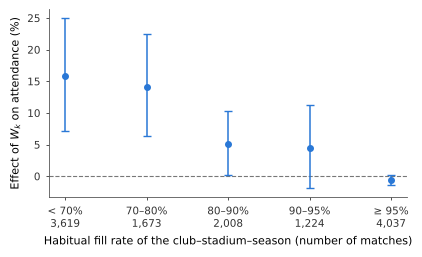

,sample,coef,erreur_type,p,n
0,"non-full club-seasons, log attendance",0.0211,0.0210,0.3151,7300
1,"real fill rate, Tobit",0.0078,0.0131,0.5511,12561


,(1),(2),(3),(4),(5) non-full,(6) Tobit
variable,,,,,,
MBCI*_k (index),0.008 (0.011),,,,,
"W_k (stakes, ex ante)",,0.059*** (0.014),0.057*** (0.014),0.057*** (0.013),0.110*** (0.023),0.056*** (0.013)
Ex-ante uncertainty,,,-0.042 (0.038),-0.050 (0.039),0.010 (0.075),0.001 (0.037)
P(home win),,,-0.007 (0.018),-0.008 (0.018),0.035 (0.032),0.163*** (0.036)
"G_k (intensity, ex post)",,-0.005 (0.005),,-0.005 (0.005),-0.014 (0.010),0.000 (0.006)
"U_k (surprise, ex post)",,0.002 (0.007),,0.008 (0.006),0.019 (0.013),-0.007 (0.007)
Observations,"14,543","14,543","14,543","14,543","7,300","12,561"
Club-stadium-seasons,862,862,862,862,395,685
Clusters (home clubs),160,160,160,160,105,156


In [34]:
import shutil
import matplotlib as mpl

EN = {"MBCI_star": "MBCI*_k (index)", "W_k": "W_k (stakes, ex ante)", "incert_exante": "Ex-ante uncertainty",
      "P_H": "P(home win)", "G_k": "G_k (intensity, ex post)", "U_k": "U_k (surprise, ex post)"}
ORDRE = ["MBCI_star", "W_k", "incert_exante", "P_H", "G_k", "U_k"]
INV = {v: k for k, v in NOMS.items()}

def etoiles(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

colonnes = {f"({i + 1})": regressions[regressions.specification == s] for i, s in enumerate(SPECS)}
colonnes["(5) non-full"] = non_pleins[non_pleins.specification == "(4) ex ante + ex post"]
colonnes["(6) Tobit"] = rempl_tobit[rempl_tobit.specification == "(4) ex ante + ex post"].rename(columns={"coef_latent": "coef"})
echantillons = {"(1)": S, "(2)": S, "(3)": S, "(4)": S, "(5) non-full": NP, "(6) Tobit": RS}

valeurs, texte = [], {}
for col, t in colonnes.items():
    t = t.assign(cle=t.variable.map(INV)).set_index("cle")
    cellule = {}
    for v in ORDRE:
        if v in t.index:
            r = t.loc[v]
            valeurs.append({"column": col, "variable": EN[v], "coef": r.coef, "se": r.erreur_type, "p": r.p})
            cellule[EN[v]] = f"{r.coef:.3f}{etoiles(r.p)} ({r.erreur_type:.3f})"
        else:
            cellule[EN[v]] = ""
    d = echantillons[col]
    cellule["Observations"] = f"{len(d):,}"
    cellule["Club-stadium-seasons"] = f"{d.unite.nunique():,}"
    cellule["Clusters (home clubs)"] = f"{d.club.nunique():,}"
    if col == "(6) Tobit":
        cellule["Within R2 / sigma"] = f"sigma = {t.sigma.iloc[0]:.3f}"
        cellule["Censored share"] = f"{t.part_censuree.iloc[0]:.1%}"
    else:
        cellule["Within R2 / sigma"] = f"{t.R2_intra.iloc[0]:.4f}"
        cellule["Censored share"] = ""
    texte[col] = cellule
table6 = pd.DataFrame(texte)
table6.index.name = "variable"
table6_num = pd.DataFrame(valeurs)

# MBCI alone in the two other samples (cited in the text and in the table note)
mbci_seul = pd.DataFrame([
    {"sample": "non-full club-seasons, log attendance", **non_pleins[non_pleins.specification == "(1) indice"].iloc[0][["coef", "erreur_type", "p", "n"]].to_dict()},
    {"sample": "real fill rate, Tobit", **rempl_tobit[rempl_tobit.specification == "(1) indice"].rename(columns={"coef_latent": "coef"}).iloc[0][["coef", "erreur_type", "p", "n"]].to_dict()},
])

ETIQ = ["< 70%", "70-80%", "80-90%", "90-95%", ">= 95%"]
fig8 = enjeu_remplissage.iloc[:len(GROUPES)].copy()
fig8.insert(0, "habitual_fill_rate", ETIQ)
fig8 = fig8.drop(columns="remplissage_habituel").rename(columns={
    "clubs_saisons": "club_stadium_seasons", "matchs": "matches", "remplissage_moyen_pct": "mean_fill_rate_pct",
    "effet_W_affluence_pct": "effect_W_0_to_1_attendance_pct", "ic95_bas_pct": "ci95_low_pct", "ic95_haut_pct": "ci95_high_pct",
    "effet_W_points_remplissage": "effect_W_0_to_1_fill_points", "p_points": "p_fill_points"})

exporter("tableau_article_affluence.xlsx", {"Table6": table6, "Table6_numbers": table6_num,
                                             "MBCI_alone": mbci_seul, "Figure8_data": fig8})

STYLE_ARTICLE = {"font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans", "font.size": 8, "axes.labelsize": 8,
                 "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "axes.linewidth": 0.6,
                 "xtick.major.width": 0.6, "ytick.major.width": 0.6, "pdf.fonttype": 42}
ETIQ_FIG = ["< 70%", "70–80%", "80–90%", "90–95%", "≥ 95%"]
with mpl.rc_context(STYLE_ARTICLE):
    largeur = 345 / 72 * 0.85
    fig, ax = plt.subplots(figsize=(largeur, largeur * 0.6))
    x = np.arange(len(fig8))
    ax.axhline(0, color="#777777", lw=0.8, ls="--", zorder=1)
    ax.errorbar(x, fig8.effect_W_0_to_1_attendance_pct,
                yerr=[fig8.effect_W_0_to_1_attendance_pct - fig8.ci95_low_pct, fig8.ci95_high_pct - fig8.effect_W_0_to_1_attendance_pct],
                fmt="o", ms=4, color="#2a78d6", elinewidth=1.1, capsize=3, zorder=2)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{e}\n{m:,}" for e, m in zip(ETIQ_FIG, fig8.matches)])
    ax.set_xlabel("Habitual fill rate of the club–stadium–season (number of matches)")
    ax.set_ylabel(r"Effect of $W_k$ on attendance (%)")
    for c in ["top", "right"]:
        ax.spines[c].set_visible(False)
    for c in ["left", "bottom"]:
        ax.spines[c].set_color("#555555")
    ax.tick_params(colors="#333333", length=2.5)
    fig.tight_layout(pad=0.3)
    pdf = DOSSIER_SORTIE / "fig_attendance_stakes_by_fill.pdf"
    fig.savefig(pdf)
    plt.show()

for dossier_fig in ICI.parent.glob("after_review_version*/Figures"):
    shutil.copy(pdf, dossier_fig / pdf.name)
    print("Copié dans", dossier_fig.parent.name + "/" + dossier_fig.name)
display(mbci_seul.round(4))
table6

## 4. Conclusion

**Données.** Les 17 732 matchs de l'article sont tous appariés à FBref, avec des dates identiques et des scores identiques, sauf deux matchs attribués sur tapis vert. L'échantillon d'analyse compte 14 543 matchs (82 %).

Les exclusions sont les suivantes :
- le huis clos (2 238 matchs) et les 873 matchs des mois à jauge réduite détectés en 2021/22 ;
- 35 affluences aberrantes, dont 14 supérieures à 115 % de la capacité réelle (erreurs de saisie) ;
- 11 matchs délocalisés et 3 matchs sur tapis vert.

Elles ne créent pas de biais de sélection : les écarts standardisés entre matchs retenus et exclus sont tous inférieurs à 0,05.

La capacité réelle des stades provient des 35 pages Wikipédia des saisons hors COVID (7 saisons × 5 championnats). Elle est attribuée à 99,9 % des matchs de ces saisons. Le taux de remplissage moyen est de 81 %, et 35 % des matchs atteignent au moins 95 % de la capacité. La Premier League (97 % de remplissage, 81 % de matchs pleins) et la Bundesliga (93 %, 66 %) s'opposent à la Liga (76 %), la Ligue 1 (71 %) et la Serie A (70 %), où 6 à 13 % seulement des matchs sont pleins.

Autre limite de mesure : les affluences arrondies au millier sont fréquentes en Bundesliga (23 %) et en Serie A (10 %).

**Résultats sur l'affluence** (à club, stade, saison et journée donnés) :
1. **L'indice composite n'est pas significativement corrélé avec l'affluence.** Passer de $MBCI^*_k = 0$ à 1 change l'affluence de +0,8 % ($p = 0{,}43$), et de +2,1 % dans les stades non pleins ($p = 0{,}32$).
2. **L'enjeu $W_k$, seule composante connue avant le match, augmente l'affluence.** L'effet est de +5,9 % quand $W_k$ passe de 0 à 1 ($p < 0{,}001$), et de +11,7 % dans les stades non pleins. Il est fort en Liga (+21 %), positif en Bundesliga ($p = 0{,}045$), proche du seuil en Serie A ($p = 0{,}11$), nul en Premier League et en Ligue 1. Il décroît à mesure que le stade se remplit : +15,8 % pour les clubs habituellement remplis à moins de 70 %, +14,1 % entre 70 et 80 %, +5,1 % entre 80 et 90 %, +4,4 % (non significatif) entre 90 et 95 %, et aucun effet au-delà (−0,6 %). Ce gradient montre que la faiblesse de l'effet moyen vient de la censure par la capacité : là où des places sont libres, un match à fort enjeu attire nettement plus de spectateurs.
3. **Les composantes ex post $G_k$ et $U_k$ ne sont pas associées à l'affluence** ($p = 0{,}34$ et $0{,}21$) : le test placebo est satisfait.
4. **L'incertitude ex ante n'est pas associée à l'affluence** ($p = 0{,}21$), comme pour les audiences télévisées dans Buraimo et al. (2022).

**Résultats sur le taux de remplissage réel** (saisons hors COVID) :
5. **Toutes équipes confondues, le remplissage n'est pas corrélé avec l'indice** ($r = 0{,}005$, $p = 0{,}56$). Entre clubs, à la même journée, l'indice est même associé à des stades moins pleins (−5,9 points de 0 à 1, $p = 0{,}009$). Les stades les plus pleins sont en effet ceux des grands clubs, dont les matchs à domicile sont plus prévisibles. Ce n'est pas un effet de la compétitivité : l'association disparaît à l'intérieur d'un club (+0,1 point, $p = 0{,}93$) et d'un club-saison (+0,7 point, $p = 0{,}38$).
6. **L'enjeu augmente le remplissage dans les trois comparaisons** : +5,0 points entre clubs ($p = 0{,}003$), +4,4 points à l'intérieur d'un club et +4,5 points à l'intérieur d'un club-saison ($p < 0{,}001$).
7. **Avec le modèle Tobit**, qui traite les 35 % de matchs pleins comme censurés, l'enjeu augmente la demande latente de 5,6 points de remplissage ($p < 0{,}001$). L'indice n'a pas d'effet (+0,8 point, $p = 0{,}55$), pas plus que $G_k$, $U_k$ et l'incertitude ex ante. La demande est aussi plus forte quand le club recevant est favori (+16 points de 0 à 1).

**Autres résultats** :
8. **Au niveau ligue-saison**, les corrélations entre $MBCI_s$ et l'affluence moyenne ($r = 0{,}43$) ou le remplissage moyen ($r = 0{,}48$) disparaissent à l'intérieur des championnats ($r = 0{,}16$ et $0{,}25$, non significatifs). Elles reflètent des différences entre pays : la Bundesliga a à la fois plus de buts et des stades plus pleins.
9. **Robustesse.** L'effet de l'enjeu tient dans toutes les variantes qui comparent des matchs au même moment de la saison. Il disparaît seulement quand le moment de la saison n'est pas contrôlé : $W_k$ croît avec $t/T$, alors que l'affluence a son propre profil saisonnier.

**Réponse à la question.** L'indice MBCI dans son ensemble n'est pas validé par l'affluence au stade, que celle-ci soit mesurée en spectateurs ou en taux de remplissage réel, et même en tenant compte des stades pleins. Sa composante d'enjeu est validée : à capacité donnée, un match à fort enjeu remplit le stade d'environ 4 à 6 points de plus. C'est le schéma attendu par l'article (Section 8) : l'affluence, décidée avant le match, répond à la composante ex ante (l'enjeu) et non aux composantes ex post (intensité, surprise réalisée). La validation de ces dernières demande des audiences télévisées mesurées pendant le match.

**Pour la révision de l'article** :
- ce résultat valide, contre un critère de demande, la composante nouvelle de l'indice, $W_k$ ;
- il justifie de présenter le MBCI composite comme une mesure de compétitivité réalisée, dont la validation complète demande des audiences en cours de match ;
- il indique que des poids estimés sur l'affluence donneraient l'essentiel du poids à l'enjeu ($\lambda$). C'est cohérent avec le choix des poids laissé à l'utilisateur : un club qui vend des billets privilégierait l'enjeu.

## Fichiers produits (`sorties_affluence/`)

| Fichier | Contenu |
|---|---|
| `fbref_calendrier_brut.xlsx` | Calendrier FBref tel que téléchargé (affluence, stade, heure, notes) |
| `capacites_stades_wikipedia.xlsx` | Capacité du stade de chaque club, par ligue-saison hors COVID, avec la page Wikipédia source |
| `donnees_affluence_mbci.xlsx` | Les 17 732 matchs de l'article avec affluence, capacité réelle, remplissage réel, composantes du MBCI, indicateurs de vérification et colonne `echantillon` |
| `controle_donnees.xlsx` | Vérification : flux de l'échantillon, complétude, appariement des noms, écarts de score, manquants, jauges COVID, valeurs aberrantes, matchs délocalisés, arrondis, capacités Wikipédia et leur attribution, affluences au-delà de la capacité, censure, biais de sélection |
| `resultats_validation.xlsx` | Analyse : échantillon, corrélations, régressions, déciles, par championnat, stades non pleins, effet de l'enjeu par niveau de remplissage, niveau ligue-saison, taux de remplissage réel (descriptif, corrélations, régressions, Tobit), robustesse |
| `fig_detection_jauges.png`, `fig_affluence_deciles.png`, `fig_enjeu_par_remplissage.png` | Figures des sections 2.4, 3.4 et 3.6 |
| `tableau_article_affluence.xlsx`, `fig_attendance_stakes_by_fill.pdf` | Tableau 6 et Figure 8 de l'article (Section 7.6), en anglais |